# Sinais de corretude em geração de código
## Experimento de desenho fixo: HumanEval+ e transferência MBPP+

Os resultados principais vêm de 2.640 trajetórias em 132 tarefas, após piloto
separado. Todos os números abaixo são lidos dos artefatos verificados.
Os dados históricos permanecem em seção separada. Não se reivindica pré-registro
independente; exposição histórica e aprovação pendente são divulgadas.


In [1]:
from pathlib import Path
import hashlib
import json
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
REPORT = ROOT / "reports/final_review"
evidence = json.loads((REPORT / "evidence.json").read_text(encoding="utf-8"))
pd.set_option("display.max_columns", 12)
pd.set_option("display.precision", 4)
display(Markdown(f"**Data de referência:** {evidence['as_of']} · **Escopo:** avaliação principal de desenho fixo"))


**Data de referência:** 2026-10-17 · **Escopo:** avaliação principal de desenho fixo

## Resultados principais em 32 tokens

Elegibilidade exige T > t. AUC agregada e AUC intratarefa respondem perguntas
diferentes. Intervalos usam 2.000 reamostragens de tarefas e não refazem o treino.


,checkpoint,trajectories,tasks,mixed_tasks,always_correct,always_wrong,pass_rate,truncation_rate
0,0,2640,132,100,12,20,0.4917,0.0
1,8,2640,132,100,12,20,0.4917,0.0
2,16,2608,132,97,15,20,0.4904,0.0
3,32,2158,132,92,20,20,0.4778,0.0
4,64,1228,122,69,27,26,0.5261,0.0
5,final,2640,132,100,12,20,0.4917,0.0


,checkpoint,predictor,roc_auc,pr_auc,log_loss,brier,within_task_auc,within_task_auc_ci95,intervals
0,32,prior,0.4302,0.4696,0.6980,0.2524,0.5000,"[0.5, 0.5]","{'roc_auc': [0.359979646055172, 0.501456956983..."
1,32,B1,0.6034,0.6194,0.6741,0.2408,0.5000,"[0.5, 0.5]","{'roc_auc': [0.5375479196232481, 0.66717108108..."
2,32,B2,0.5858,0.5994,0.6851,0.2459,0.5000,"[0.5, 0.5]","{'roc_auc': [0.5122477668159725, 0.65077062769..."
3,32,B3,0.6971,0.6975,0.6316,0.2207,0.6242,"[0.5787962310004986, 0.6705630974619681]","{'roc_auc': [0.6412298273545215, 0.74882963185..."
4,32,B,0.7005,0.7197,0.6302,0.2199,0.6282,"[0.5833350933801488, 0.6745308482009916]","{'roc_auc': [0.6449493127422833, 0.75162936667..."
5,32,H,0.5924,0.5837,0.6869,0.2460,0.5681,"[0.5211626336576727, 0.613747242378988]","{'roc_auc': [0.5381122906813566, 0.64158548584..."
6,32,HB,0.6456,0.6231,0.6681,0.2362,0.5811,"[0.5337048357184878, 0.6294412122364857]","{'roc_auc': [0.5914193427490239, 0.69475706968..."
7,32,random_direction,0.4356,0.4631,0.6978,0.2523,0.4962,"[0.4530269792152766, 0.5376889252771644]","{'roc_auc': [0.37006678556399686, 0.5015203241..."
8,32,shuffled_training_labels,0.6048,0.6206,0.6924,0.2480,0.5338,"[0.4885513610272904, 0.5786055312655672]","{'roc_auc': [0.5479863509590684, 0.65478513780..."
9,32,length_stopping,0.4302,0.4696,0.6980,0.2524,0.5000,"[0.5, 0.5]","{'roc_auc': [0.359979646055172, 0.501456956983..."


{'supported': False,
 'checkpoint': 32,
 'delta_hb_minus_b': {'estimate': -0.04702865751183576,
  'ci95': [-0.09937495818447424, 0.005583498622638421],
  'tasks': 92,
  'replications': 2000,
  'seed': 20260921,
  'unit': 'task_id'},
 'descriptive_delta_h_minus_b': {'estimate': -0.06004633395733728,
  'ci95': [-0.1143251150204028, -0.003948685130266649],
  'tasks': 92,
  'replications': 2000,
  'seed': 20260921,
  'unit': 'task_id'},
 'permutation': {'p_value': 0.030996900309969003,
  'folds': [{'fold': 0,
    'p_value': 0.1100889911008899,
    'observed_wt_auc': 0.558784776511577,
    'mixed_tasks': 19,
    'seed': 20260921},
   {'fold': 1,
    'p_value': 0.006199380061993801,
    'observed_wt_auc': 0.594928908515974,
    'mixed_tasks': 22,
    'seed': 20260922},
   {'fold': 2,
    'p_value': 0.017598240175982403,
    'observed_wt_auc': 0.5929434742363664,
    'mixed_tasks': 18,
    'seed': 20260923},
   {'fold': 3,
    'p_value': 0.07879212078792121,
    'observed_wt_auc': 0.568611816

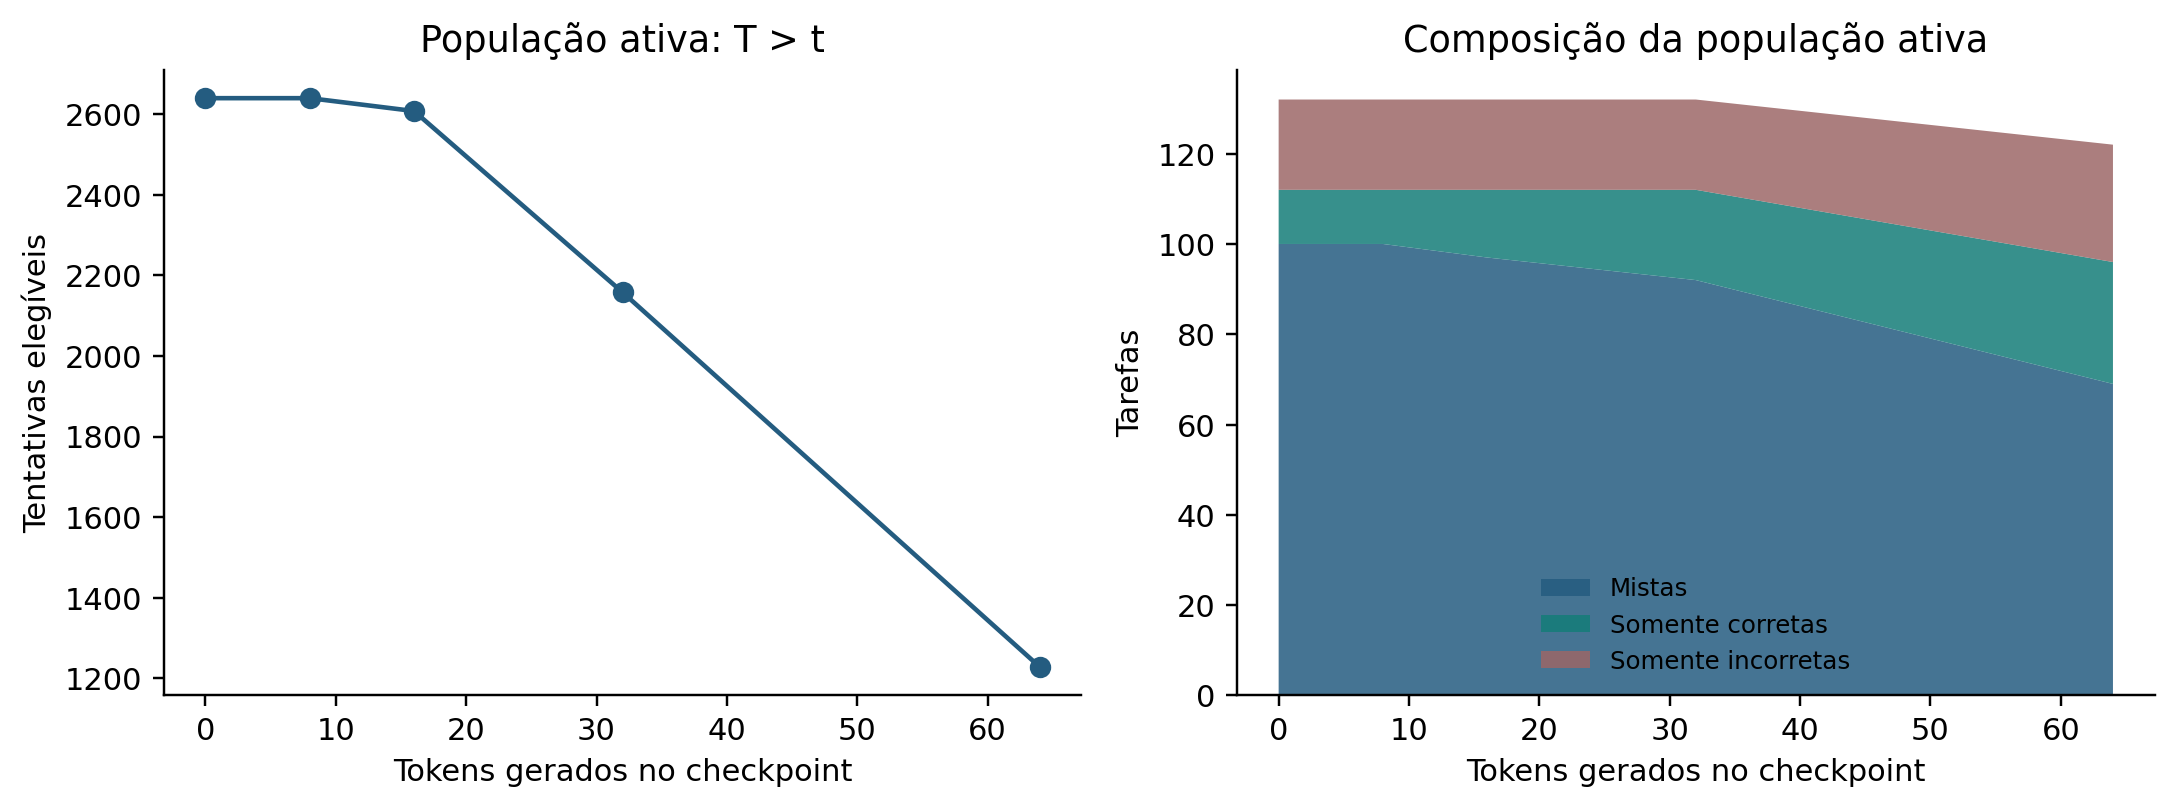

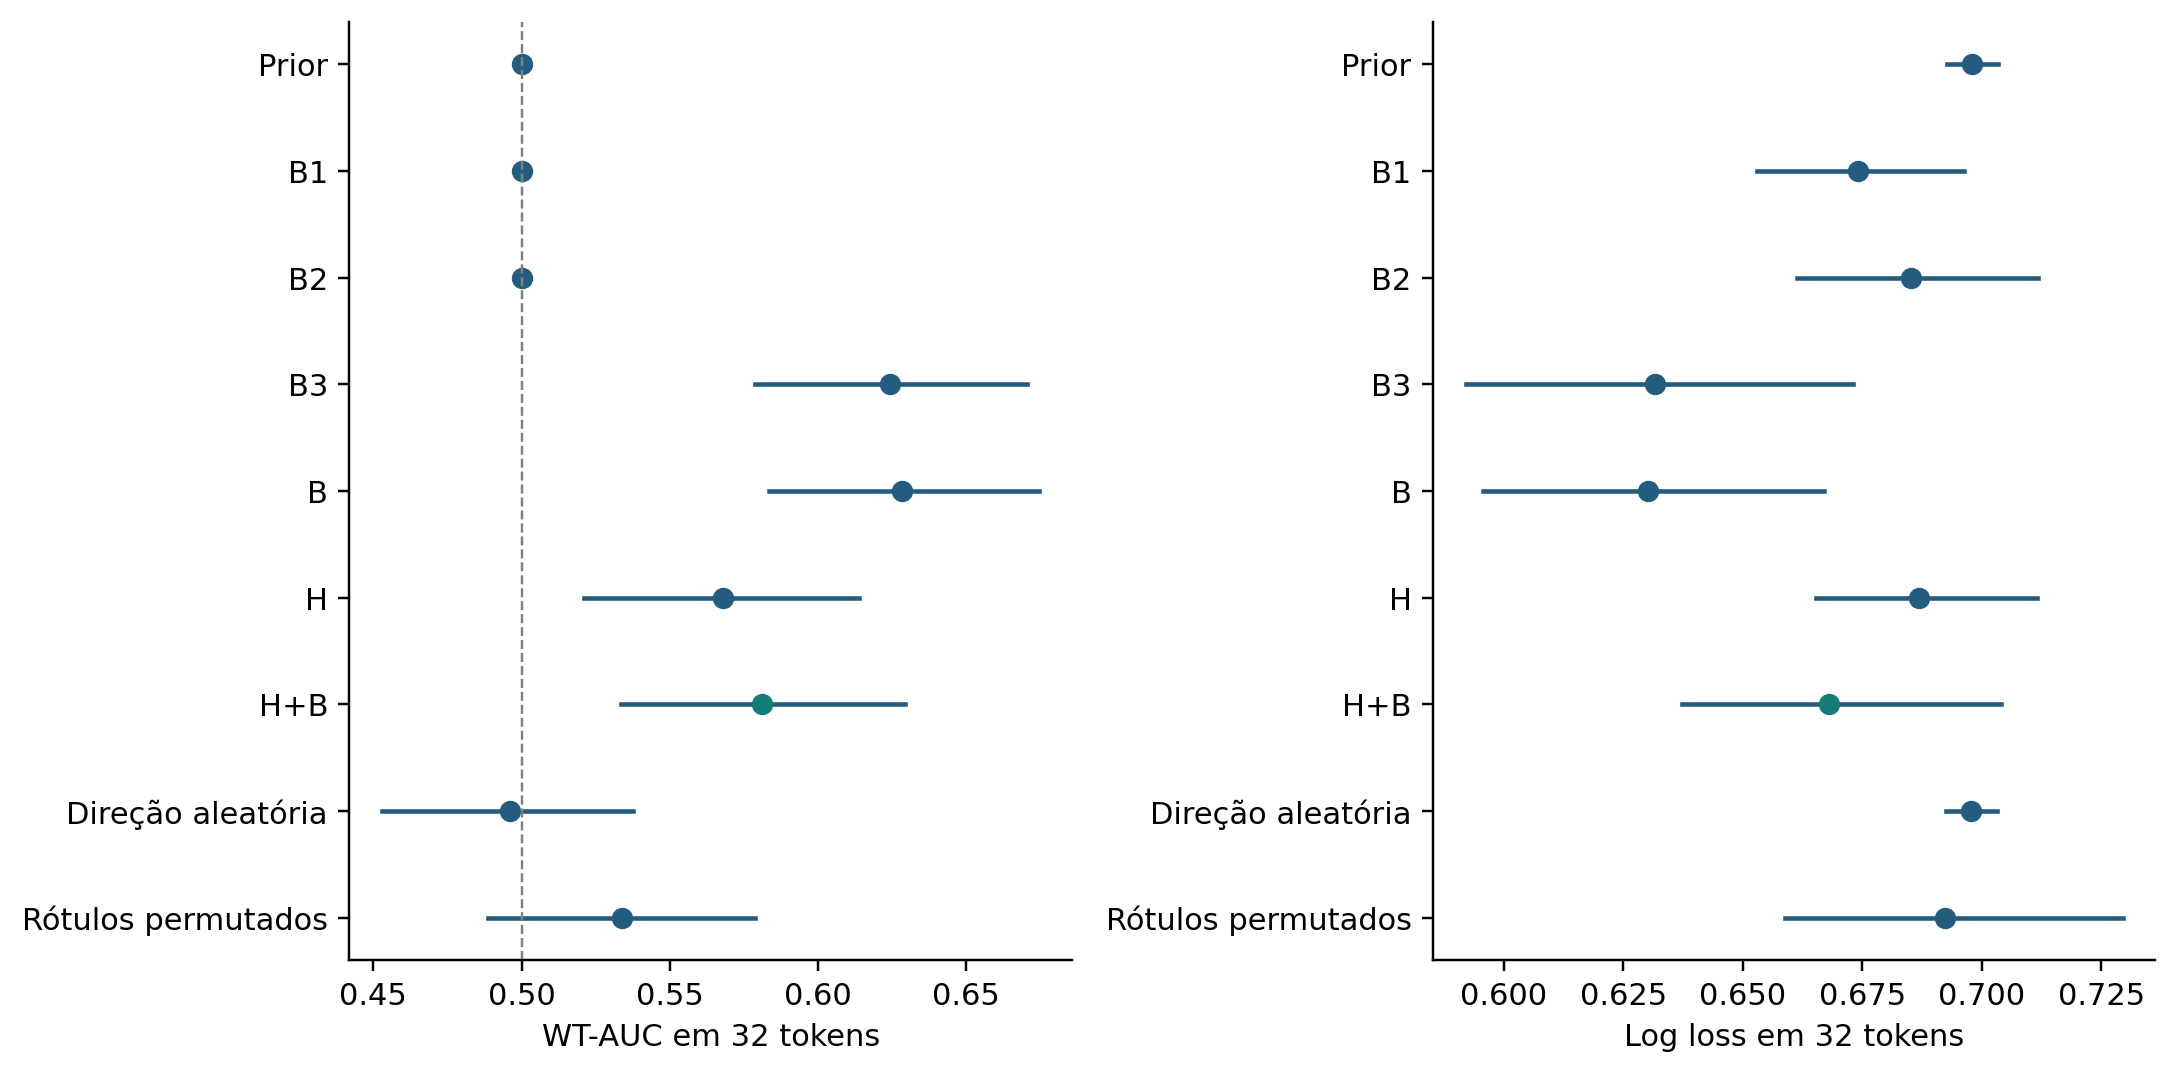

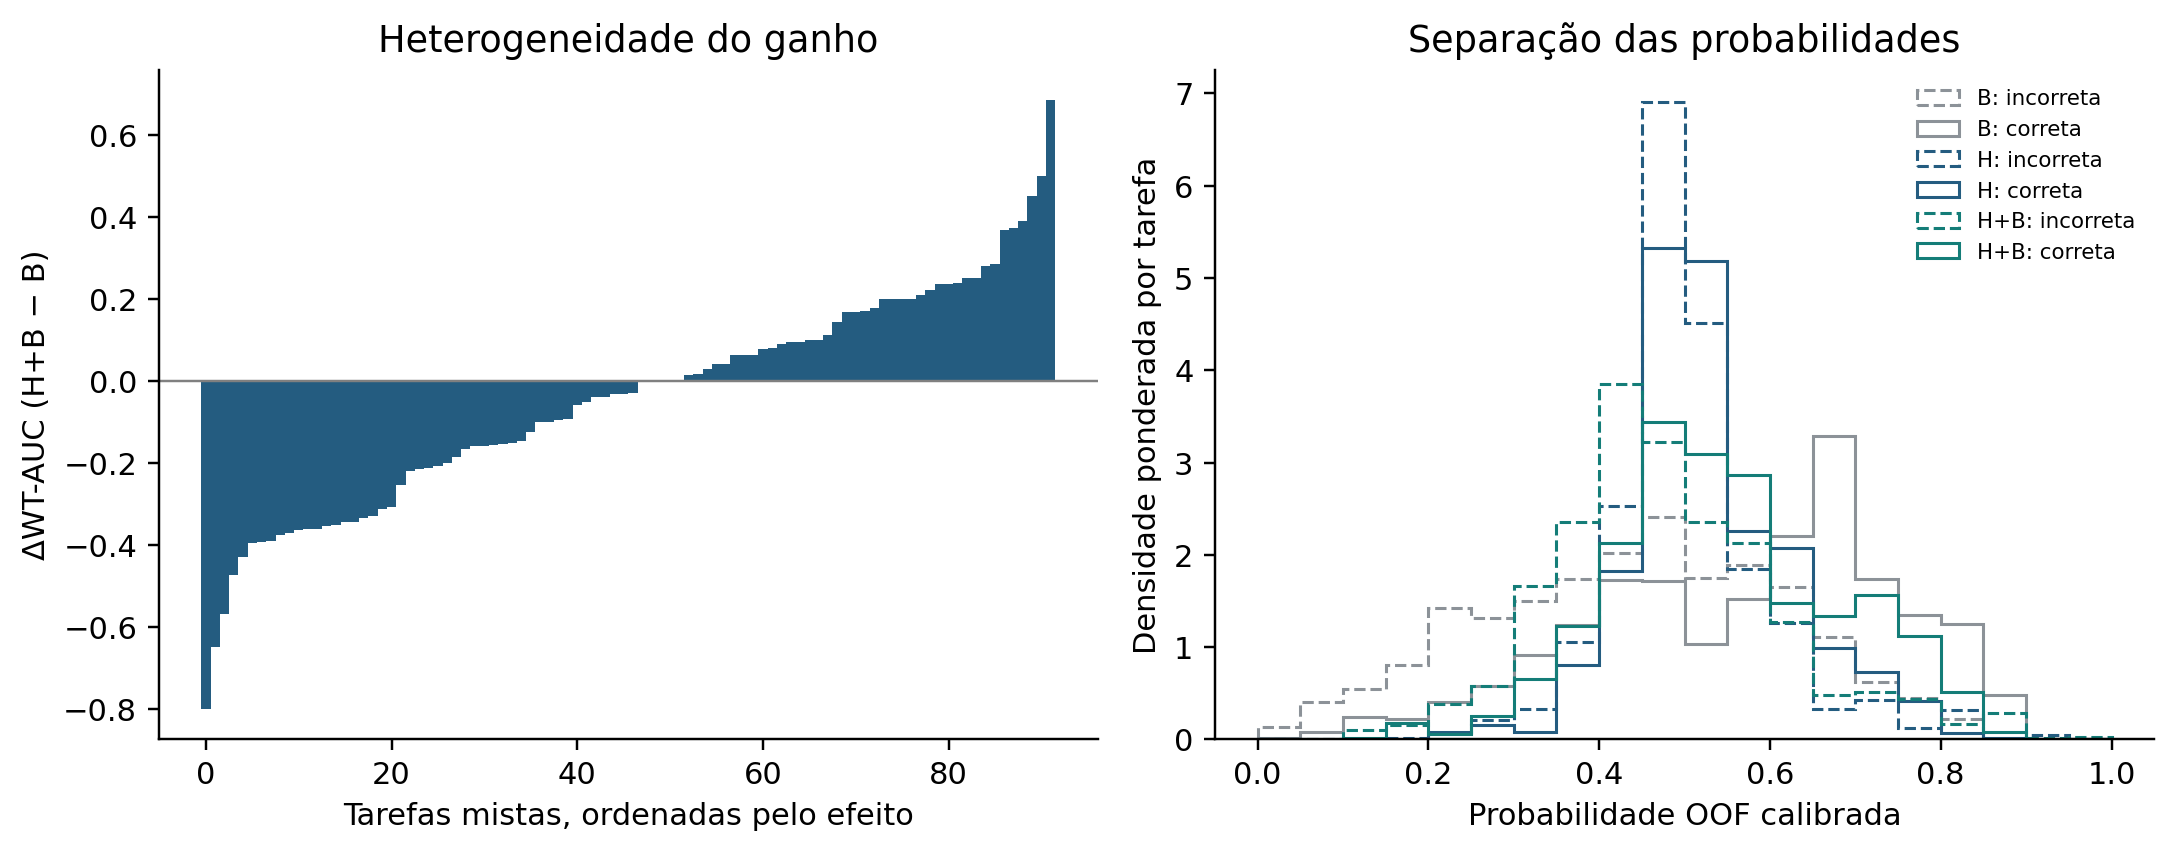

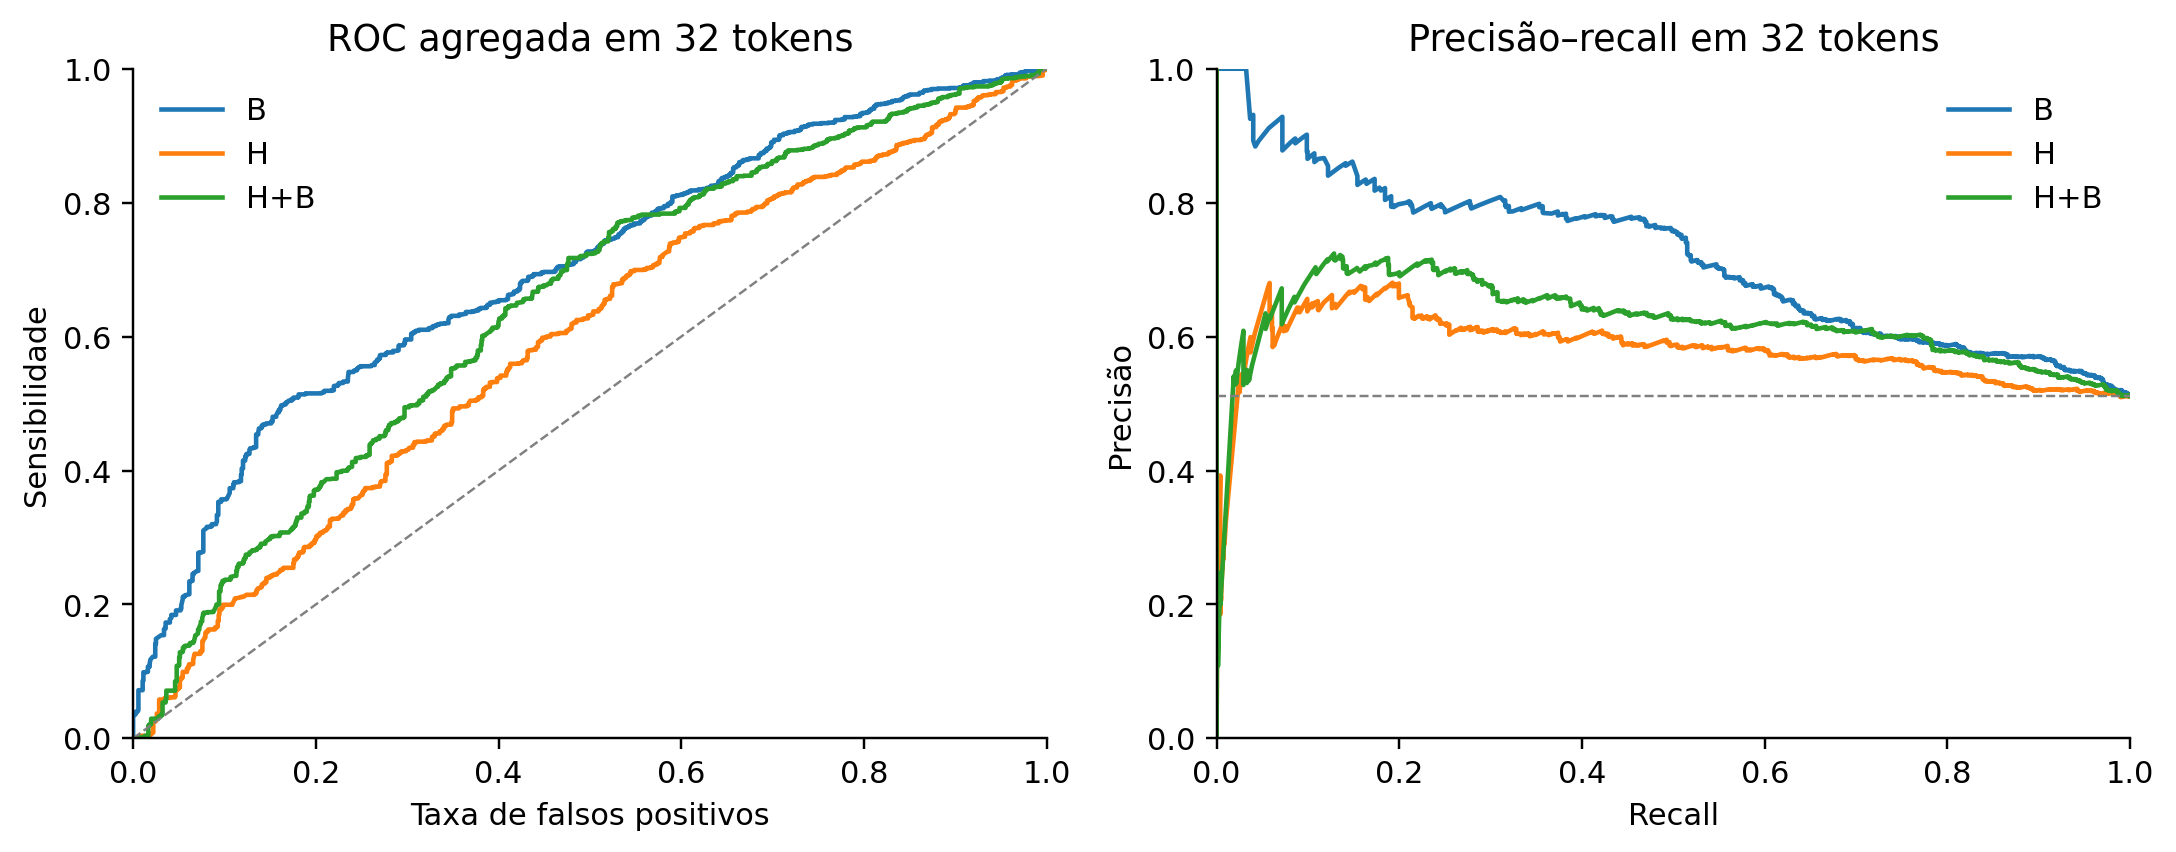

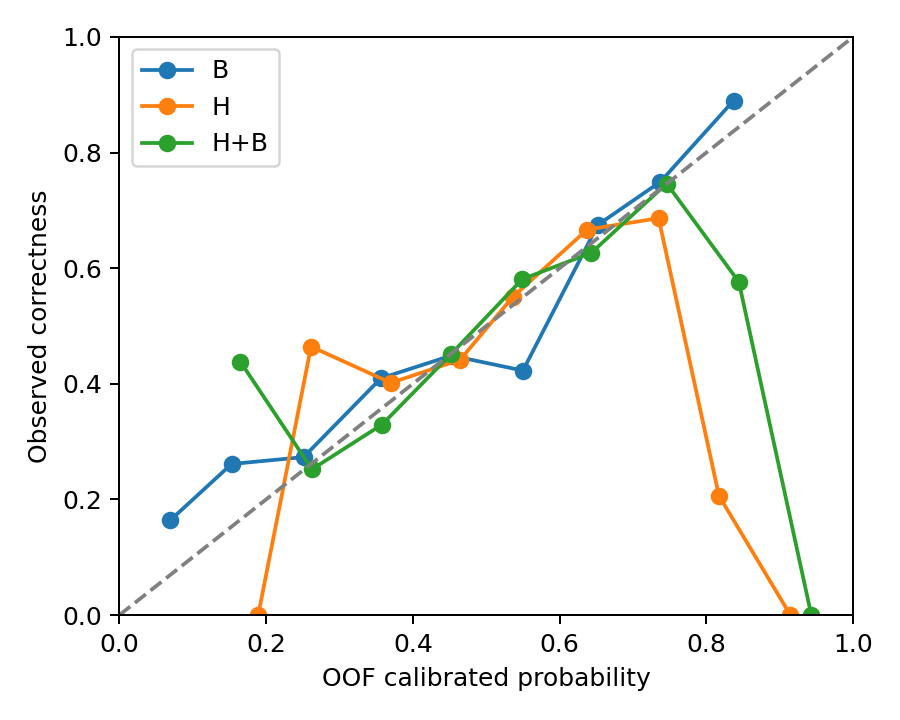

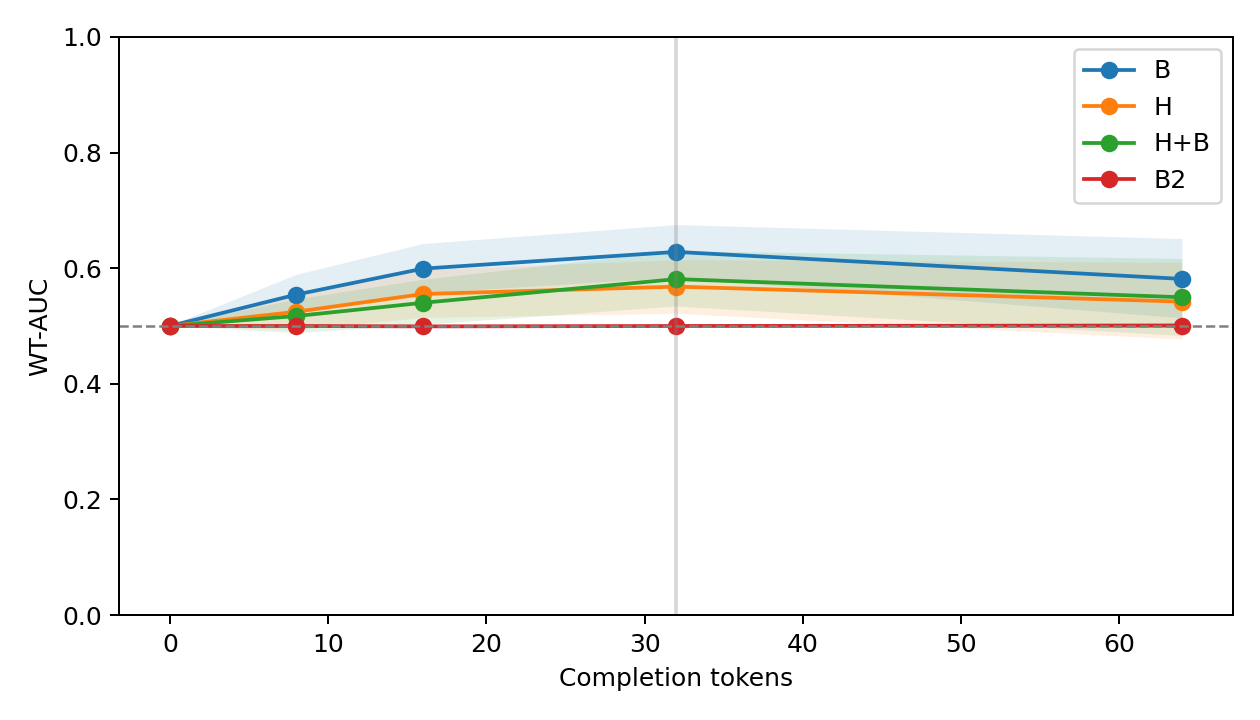

In [2]:
main = evidence["main"]
signal, policies = main["signal"], main["policies"]
display(pd.DataFrame(signal["risk_sets"]))
display(pd.DataFrame([r for r in signal["metrics"] if r["checkpoint"] == "32"]))
display(signal["H2"])
for name in ["risk_set_attrition", "primary_predictor_comparison", "primary_task_deltas", "primary_roc_pr"]:
    display(Image(filename=str(ROOT / f"reports/protocol_v0.2/figures/{name}.png")))
display(Image(filename=str(ROOT / "reports/protocol_v0.2/figures/calibration_32.png")))
display(Image(filename=str(ROOT / "reports/protocol_v0.2/figures/within_task_discrimination.png")))


## Utilidade operacional: custo, resolução e risco

As políticas usam as mesmas sementes e contam apenas tentativas iniciadas.
A margem de resolução é −0,03. Economia de tokens não implica menor latência.


,budget,policy,tasks,resolution,completion_tokens_per_task,attempts_started_per_task,fully_generated_attempts_per_task,correct_false_abort_rate,active_correct_false_abort_rate,correct_attempts_started,active_correct_attempts_started
0,1,B,132,0.4621,68.6894,1.0000,0.9394,0.0317,0.0333,63,60
1,1,HB,132,0.4697,70.2500,1.0000,0.9621,0.0159,0.0189,63,53
2,1,fixed,132,0.4773,72.2197,1.0000,1.0000,0.0000,0.0000,63,51
3,1,verifier,132,0.4773,72.2197,1.0000,1.0000,0.0000,0.0000,63,51
4,5,B,132,0.6591,189.9697,2.7273,2.4394,0.1386,0.1458,101,96
5,5,HB,132,0.6742,192.0303,2.6818,2.5000,0.0825,0.0964,97,83
6,5,fixed,132,0.6970,372.4318,5.0000,5.0000,0.0000,0.0000,316,255
7,5,verifier,132,0.6970,199.9394,2.6212,2.6212,0.0000,0.0000,92,75
8,10,B,132,0.7500,296.0227,4.1515,3.6288,0.1885,0.1966,122,117
9,10,HB,132,0.7727,300.1818,3.9697,3.6742,0.0893,0.1031,112,97


,budget,comparison,resolution_delta,token_delta
0,1,HB minus verifier,"{'estimate': -0.007575757575757576, 'ci95': [-...","{'estimate': -1.9696969696969697, 'ci95': [-4...."
1,1,HB minus B,"{'estimate': 0.007575757575757576, 'ci95': [-0...","{'estimate': 1.5606060606060606, 'ci95': [-2.2..."
2,5,HB minus verifier,"{'estimate': -0.022727272727272728, 'ci95': [-...","{'estimate': -7.909090909090909, 'ci95': [-18...."
3,5,HB minus B,"{'estimate': 0.015151515151515152, 'ci95': [-0...","{'estimate': 2.0606060606060606, 'ci95': [-12...."
4,10,HB minus verifier,"{'estimate': -0.022727272727272728, 'ci95': [-...","{'estimate': -10.363636363636363, 'ci95': [-25..."
5,10,HB minus B,"{'estimate': 0.022727272727272728, 'ci95': [-0...","{'estimate': 4.159090909090909, 'ci95': [-23.0..."
6,20,HB minus verifier,"{'estimate': -0.015151515151515152, 'ci95': [-...","{'estimate': -7.181818181818182, 'ci95': [-18...."
7,20,HB minus B,"{'estimate': 0.022727272727272728, 'ci95': [-0...","{'estimate': 12.962121212121213, 'ci95': [-26...."


{'offline_statistical_support': False,
 'online_replay_validated': True,
 'incremental_over_observables': False,
 'system_result_finalized': False,
 'primary_budget': 20,
 'h2_supported': False,
 'operational_benefit_claim_supported': False,
 'interpretation': 'Predeclared diagnostic only; no operational benefit claim when H2 is unsupported'}

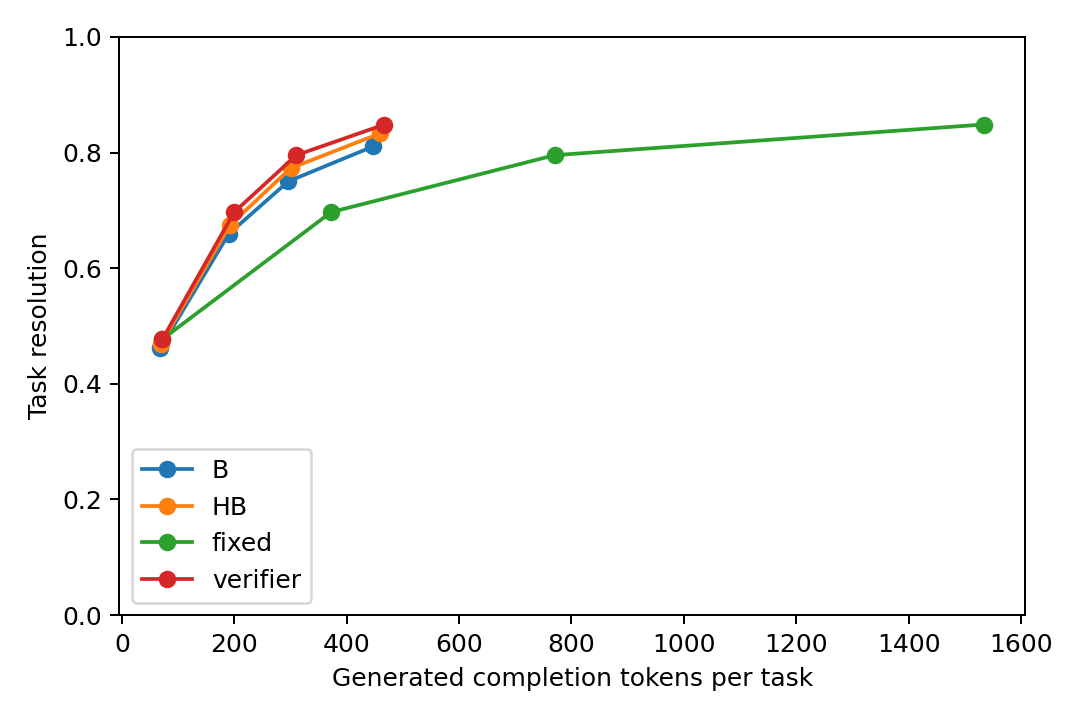

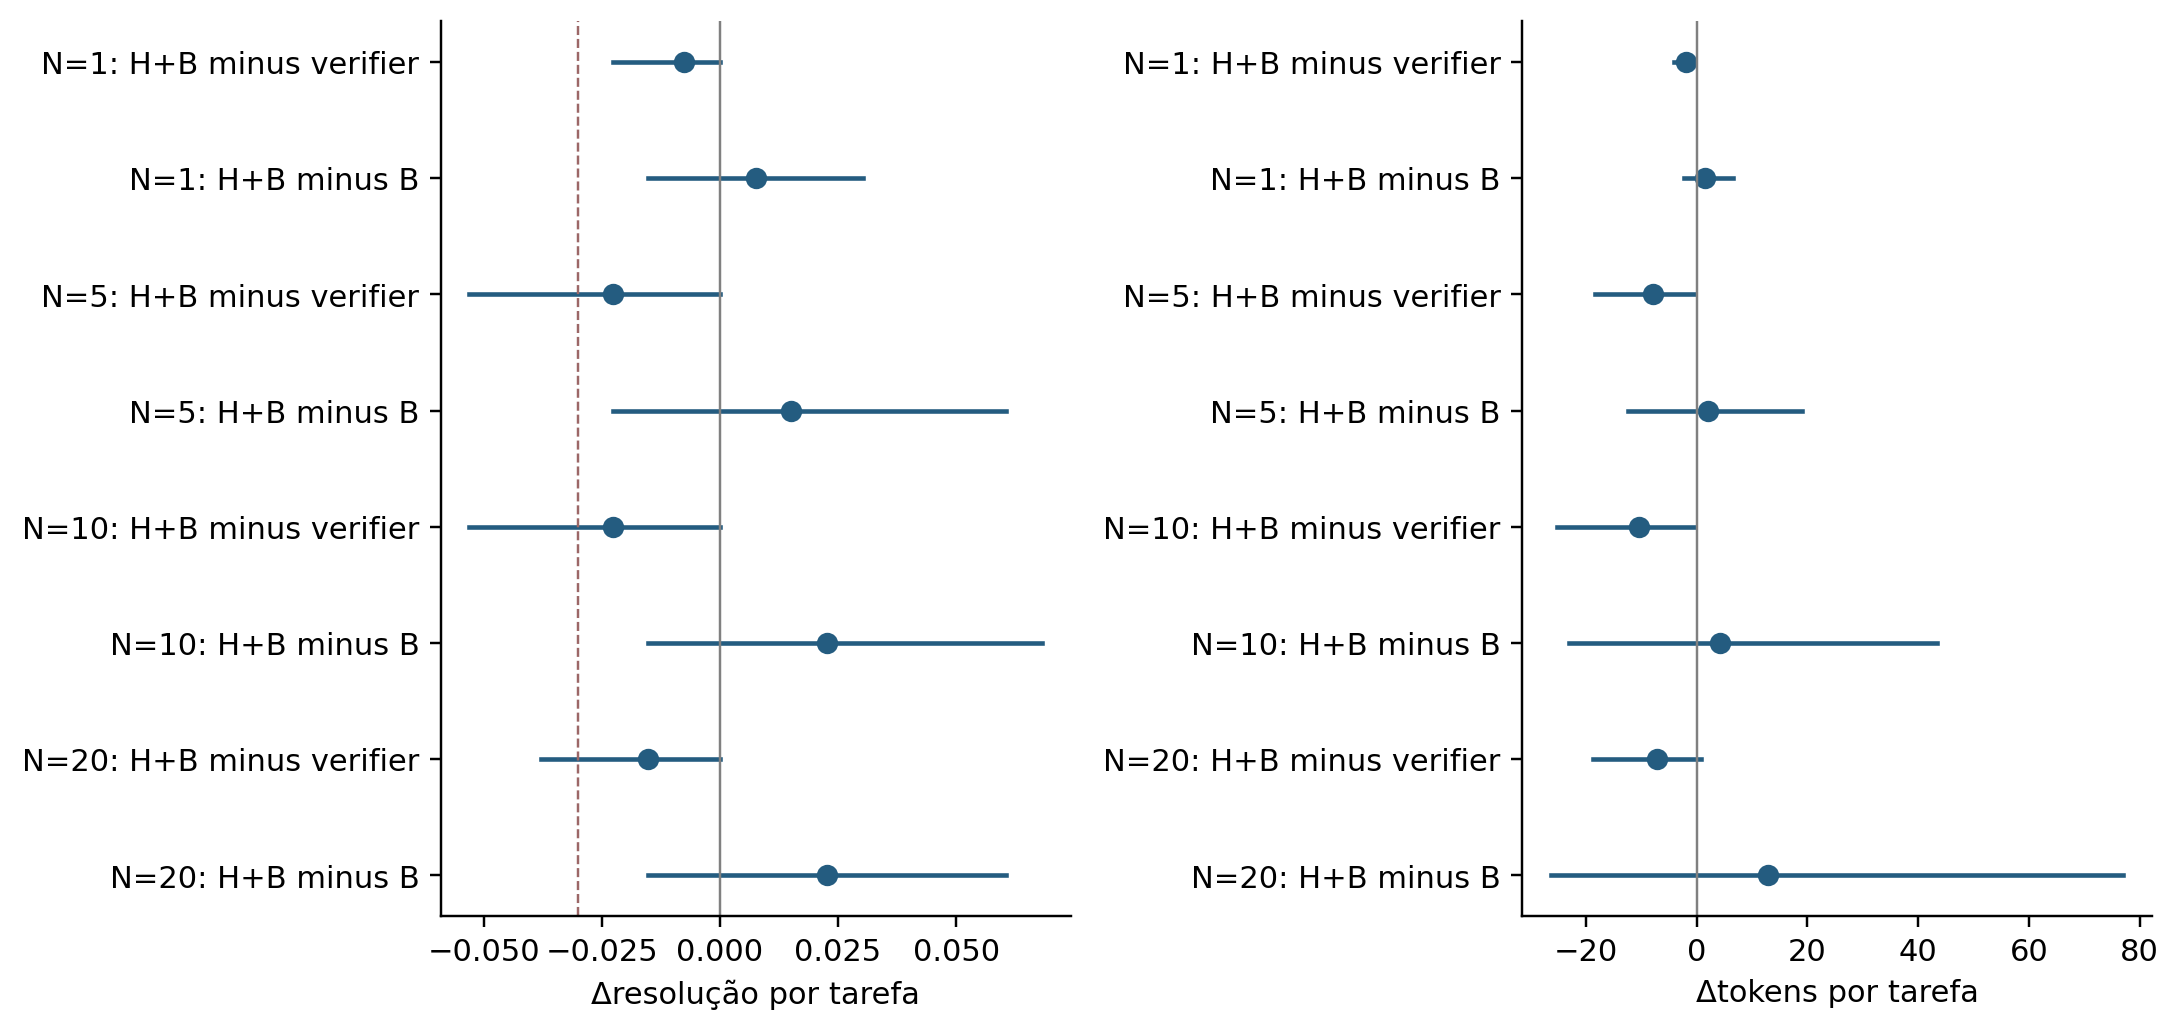

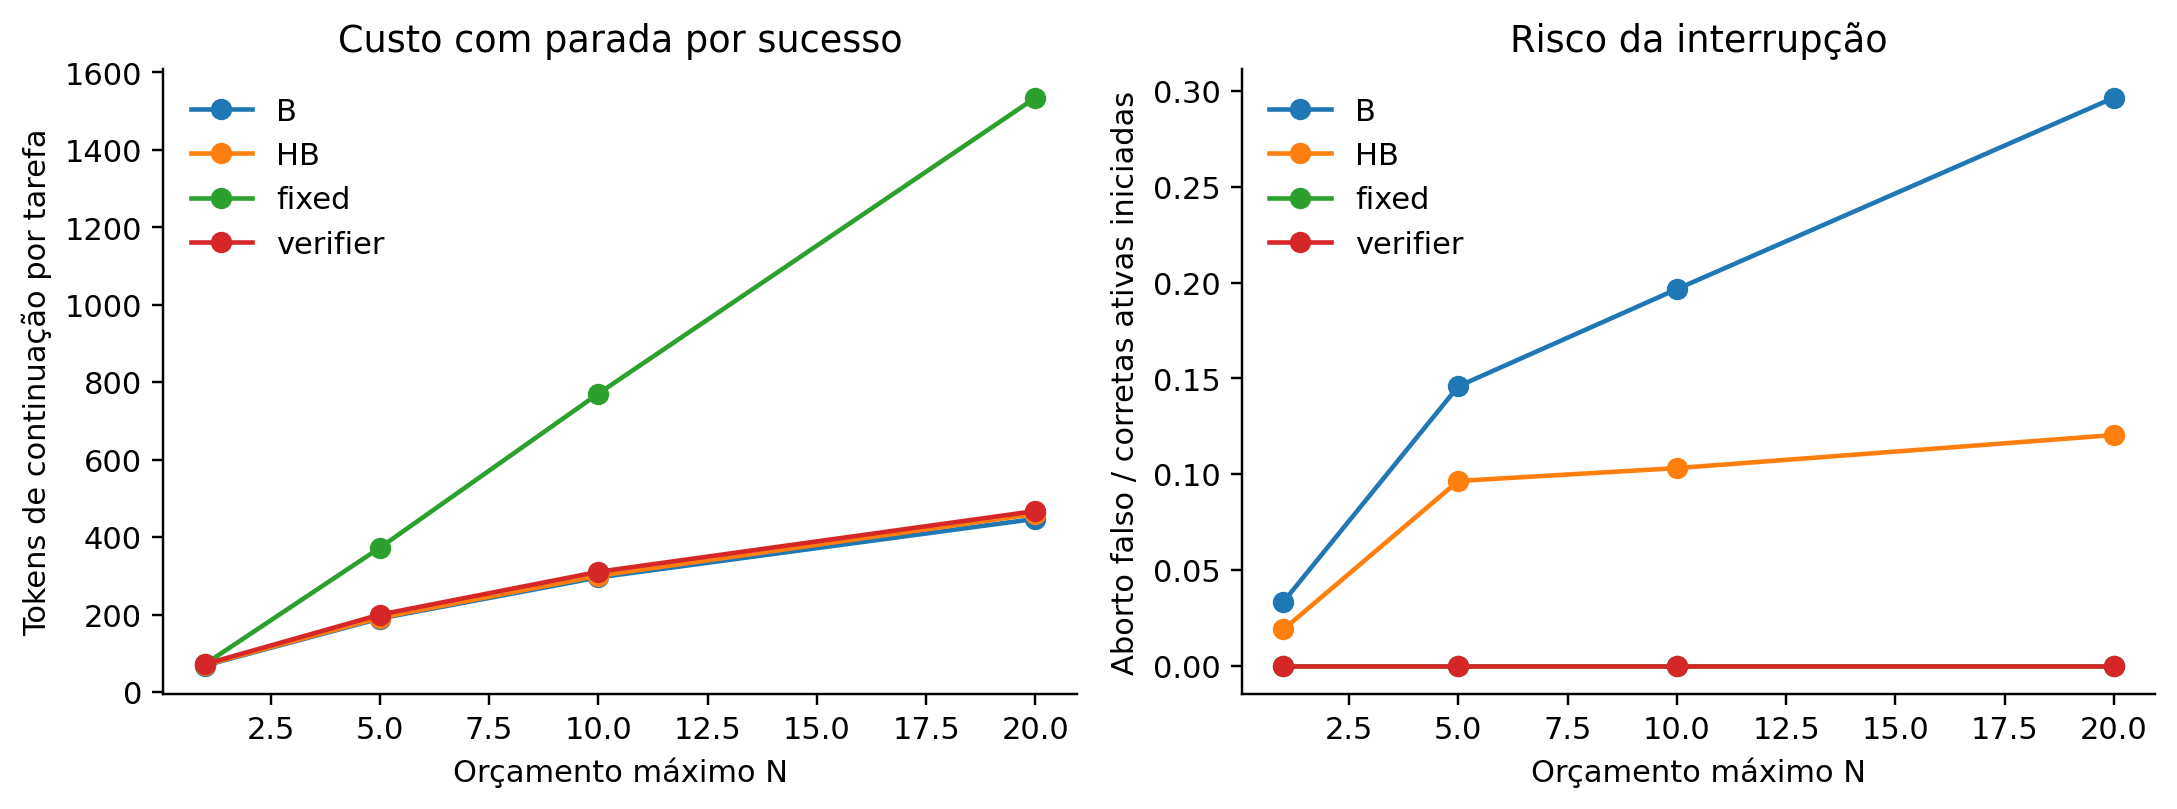

**Q2:** não sustentada pelos critérios definidos. **Benefício operacional conjunto:** False. Um resultado negativo ou inconclusivo é preservado na conclusão.

,task_id,policy,passed,completion_tokens,fully_generated_attempts,resolved,...,generation_seconds,verification_seconds,score_seconds_included_in_generation,aborted_attempts,total_seconds,prompt_prefill_tokens
0,HumanEval/0,verifier,True,98,1,1,...,11.4536,0.0765,0.0000,0,11.5301,174
1,HumanEval/0,B,True,98,1,1,...,11.1679,0.0225,0.0037,0,11.1904,174
2,HumanEval/0,HB,True,98,1,1,...,11.2347,0.0223,0.0006,0,11.2570,174
3,HumanEval/1,B,True,194,1,1,...,22.0337,0.0178,0.0006,0,22.0515,165
4,HumanEval/1,HB,True,194,1,1,...,21.8925,0.0216,0.0009,0,21.9141,165
5,HumanEval/1,verifier,True,194,1,1,...,22.0554,0.0189,0.0000,0,22.0742,165
6,HumanEval/10,HB,True,371,2,1,...,42.4084,0.0594,0.0012,0,42.4678,384
7,HumanEval/10,verifier,True,371,2,1,...,41.9437,0.0496,0.0000,0,41.9933,384
8,HumanEval/10,B,True,371,2,1,...,41.9296,0.0440,0.0017,0,41.9736,384
9,HumanEval/100,verifier,True,602,7,1,...,69.3246,7.1846,0.0000,0,76.5092,1274


Tempos online descritivos: tarefas pré-selecionadas por ID, ordem das políticas rotacionada e aquecimento excluído; sem inferência de latência.

In [3]:
display(pd.DataFrame(policies["summaries"]))
display(pd.DataFrame(policies["comparisons"]))
display(policies["H3"])
for name in ["compute_resolution", "paired_policy_effects", "policy_cost_and_false_aborts"]:
    display(Image(filename=str(ROOT / f"reports/protocol_v0.2/figures/{name}.png")))
decision = "sustentada pelos critérios definidos" if signal["H2"]["supported"] else "não sustentada pelos critérios definidos"
display(Markdown(f"**Q2:** {decision}. **Benefício operacional conjunto:** "
                 f"{policies['H3']['operational_benefit_claim_supported']}. "
                 "Um resultado negativo ou inconclusivo é preservado na conclusão."))
if "online" in evidence:
    display(pd.DataFrame(evidence["online"]["validations"]))
    display(Markdown("Tempos online descritivos: tarefas pré-selecionadas por ID, "
                     "ordem das políticas rotacionada e aquecimento excluído; sem inferência de latência."))


## Transferência externa congelada

Modelos, calibradores e limiares ajustados somente em HumanEval+.
Os rótulos MBPP+ são usados para avaliar, sem recalibração ou retreino.


,checkpoint,family,roc_auc,pr_auc,log_loss,brier,within_task_auc,intervals
0,8,B,0.4700,0.5782,0.7181,0.2622,0.5449,"{'roc_auc': [0.33791715360365604, 0.6147177725..."
1,8,H,0.3725,0.4897,0.8800,0.3311,0.5016,"{'roc_auc': [0.2628473901209153, 0.48717450913..."
2,8,HB,0.3636,0.4866,0.8828,0.3314,0.4940,"{'roc_auc': [0.2508656911444935, 0.48272663934..."
3,16,B,0.7254,0.7625,0.6588,0.2334,0.7151,"{'roc_auc': [0.6257472388676385, 0.82013598370..."
4,16,H,0.6099,0.7029,0.6732,0.2403,0.5376,"{'roc_auc': [0.5050767063310742, 0.70282400605..."
5,16,HB,0.6441,0.7211,0.6629,0.2354,0.6181,"{'roc_auc': [0.5432756200506138, 0.73406350956..."
6,32,B,0.7562,0.8104,0.6478,0.2257,0.6423,"{'roc_auc': [0.6290372243299441, 0.86073456925..."
7,32,H,0.7064,0.6820,0.6579,0.2324,0.6261,"{'roc_auc': [0.5922351288504264, 0.80724032321..."
8,32,HB,0.7330,0.7281,0.6398,0.2229,0.6427,"{'roc_auc': [0.6144274083326312, 0.83547127524..."
9,64,B,0.9152,0.9164,0.5899,0.1994,0.8472,"{'roc_auc': [0.8094948872473877, 0.98742502760..."


,checkpoint,mixed_tasks,delta_wt_auc
0,8,24,"{'estimate': -0.05086256972552442, 'ci95': [-0..."
1,16,24,"{'estimate': -0.09699238644768832, 'ci95': [-0..."
2,32,18,"{'estimate': 0.00040655150949269993, 'ci95': [..."
3,64,6,"{'estimate': -0.3055555555555555, 'ci95': [-0...."


,budget,policy,tasks,resolution,completion_tokens_per_task,attempts_started_per_task,fully_generated_attempts_per_task,correct_false_abort_rate,active_correct_false_abort_rate,correct_attempts_started,active_correct_attempts_started
0,1,B,32,0.5312,44.6875,1.0000,0.9375,0.0000,0.0000,17,17
1,1,HB,32,0.4375,43.9062,1.0000,0.8750,0.1765,0.1765,17,17
2,1,fixed,32,0.5312,47.3438,1.0000,1.0000,0.0000,0.0000,17,8
3,1,verifier,32,0.5312,47.3438,1.0000,1.0000,0.0000,0.0000,17,8
4,5,B,32,0.7500,111.7500,2.3438,2.0312,0.0769,0.0769,26,26
5,5,HB,32,0.7188,126.3438,2.6250,2.1875,0.2812,0.2812,32,32
6,5,fixed,32,0.7812,245.2812,5.0000,5.0000,0.0000,0.0000,86,45
7,5,verifier,32,0.7812,128.6875,2.3125,2.3125,0.0000,0.0000,25,14
8,10,B,32,0.8438,162.3438,3.2812,2.9375,0.0690,0.0690,29,29
9,10,HB,32,0.7500,176.4375,3.9062,3.0000,0.4146,0.4146,41,41


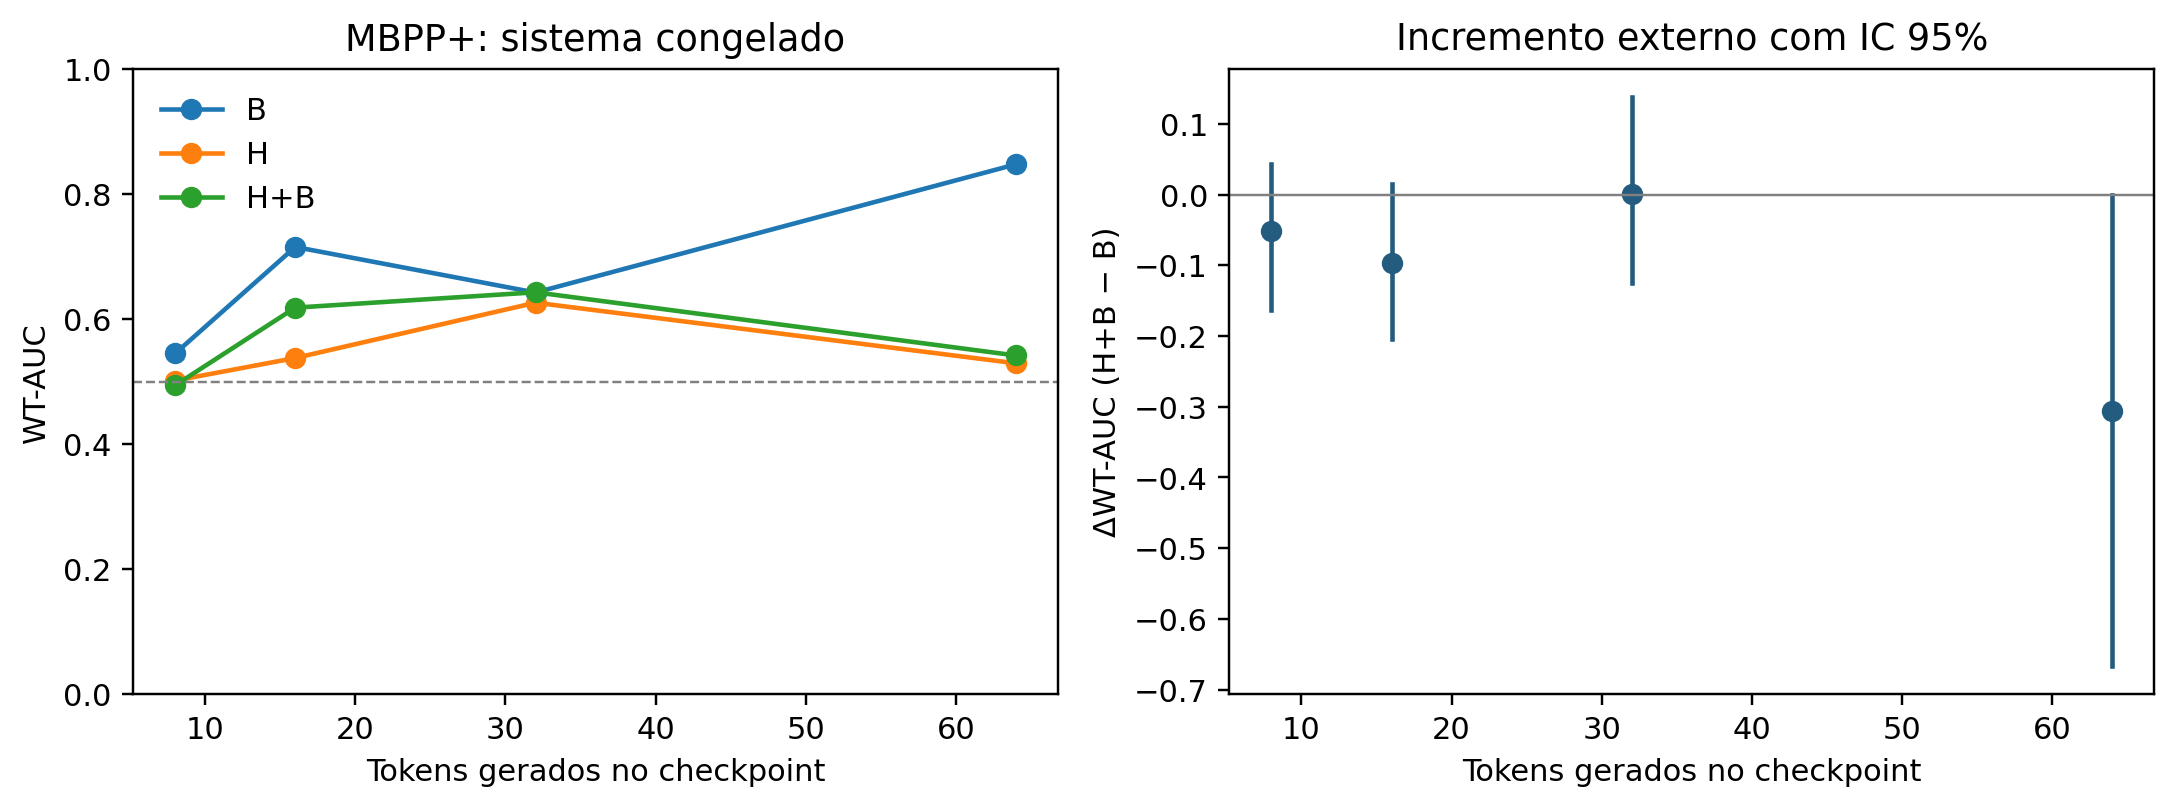

In [4]:
if "transfer" in evidence:
    display(pd.DataFrame(evidence["transfer"]["metrics"]))
    display(pd.DataFrame(evidence["transfer"]["deltas"]))
    display(pd.DataFrame(evidence["transfer"]["policies"]["summaries"]))
    display(Image(filename=str(ROOT / "reports/transfer_v0.2/figures/frozen_transfer_signal.png")))
else:
    display(Markdown("Transferência ainda pendente; nenhum resultado é inferido."))


## Diagnósticos exploratórios após a análise principal

Estes diagnósticos foram definidos depois da inspeção dos resultados. Mantêm
modelos, calibradores, limiares e critérios principais congelados. Os intervalos
adicionais são pontuais, sem correção para comparações múltiplas, condicionais
aos escores fixos. Folds compartilham dados de treino; não são replicações
independentes. A exclusão de uma tarefa não refaz o treinamento.


**Reprodução dos contrastes principais:**

{'within_task_auc': {'matches': True,
  'effect': {'estimate': -0.04702865751183576,
   'ci95': [-0.09937495818447424, 0.005583498622638421],
   'tasks': 92,
   'replications': 2000,
   'seed': 20260921,
   'unit': 'task_id'}},
 'log_loss': {'matches': True,
  'effect': {'estimate': 0.03785060488521885,
   'ci95': [0.006657260077646494, 0.0706158375881566],
   'tasks': 132,
   'replications': 2000,
   'seed': 20260921,
   'unit': 'task_id'}}}

,metric,overall_delta,leave_one_out_range,sign_preserved_all_deletions,largest_absolute_influence_task
0,brier,0.0163,"[0.014487779393501704, 0.018113173007076485]",True,HumanEval/44
1,log_loss,0.0379,"[0.03247336755322134, 0.042036992041204896]",True,HumanEval/26
2,within_task_auc,-0.0470,"[-0.05506425293851296, -0.03875424715482297]",True,HumanEval/26


,fold,attempts,tasks,comparison,metric,effect.estimate,effect.ci95,effect.tasks,effect.replications,effect.seed,effect.unit
0,0,452,27,HB minus B,within_task_auc,-0.1336,"[-0.2703631686872684, 0.010652575119940092]",19,2000,20260921,task_id
1,0,452,27,HB minus B,log_loss,0.1064,"[0.024800972542704875, 0.19180214512039098]",27,2000,20260921,task_id
2,0,452,27,HB minus B,brier,0.0424,"[0.008887277105960992, 0.0761736079378796]",27,2000,20260921,task_id
3,1,464,27,HB minus B,within_task_auc,-0.0149,"[-0.08820499297939134, 0.058782825857483297]",22,2000,20260921,task_id
4,1,464,27,HB minus B,log_loss,0.0417,"[0.004246085974881867, 0.0798096257825453]",27,2000,20260921,task_id
5,1,464,27,HB minus B,brier,0.0201,"[0.0026493222643806367, 0.0377693855139534]",27,2000,20260921,task_id
6,2,382,26,HB minus B,within_task_auc,0.0377,"[-0.07791168954955718, 0.14659686486126436]",18,2000,20260921,task_id
7,2,382,26,HB minus B,log_loss,-0.0172,"[-0.10047666239103392, 0.059356901247912715]",26,2000,20260921,task_id
8,2,382,26,HB minus B,brier,-0.0060,"[-0.04142903853945942, 0.026939492803501164]",26,2000,20260921,task_id
9,3,448,26,HB minus B,within_task_auc,-0.1265,"[-0.26927992167146575, 0.014019708412982548]",17,2000,20260921,task_id


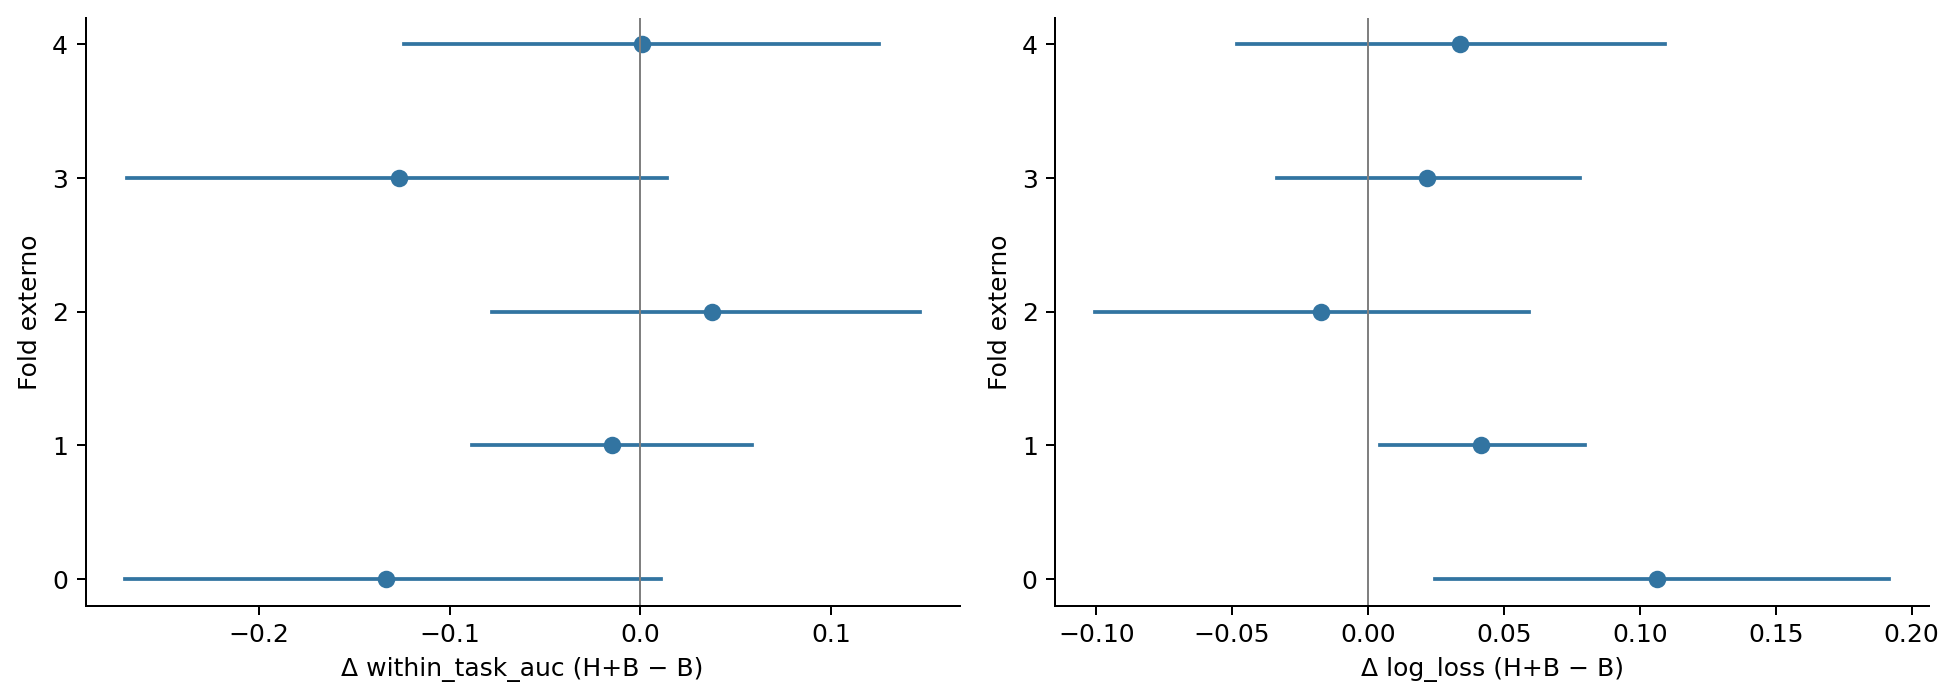

In [5]:
extra = evidence["supplemental"]
SUPPLEMENT = REPORT / "supplemental"
display(Markdown("**Reprodução dos contrastes principais:**"))
display(extra["primary_reproduction"])
display(pd.DataFrame(extra["influence_summary"]))
display(pd.json_normalize([r for r in extra["fold_contrasts"]
                          if r["comparison"] == "HB minus B"]))
display(Image(filename=str(SUPPLEMENT / "figures/fold_stability.png")))


### Mesmas tentativas e sensibilidade ao histórico

A coorte comum conserva as identidades presentes em 8, 16, 32 e 64 tokens,
condicionando em T > 64. Ela não identifica um efeito causal do tempo.
Excluir tarefas históricas só modifica a avaliação; não remove a exposição
anterior da pesquisa nem cria uma nova amostra confirmatória.


,dataset,cohort,checkpoint,attempts,tasks,comparison,...,effect.estimate,effect.ci95,effect.tasks,effect.replications,effect.seed,effect.unit
0,HumanEval+ OOF,original_risk_set,32,2158,132,HB minus B,...,-4.7029e-02,"[-0.09937495818447424, 0.005583498622638421]",92,2000,20260921,task_id
1,HumanEval+ OOF,original_risk_set,32,2158,132,HB minus B,...,3.7851e-02,"[0.006657260077646494, 0.0706158375881566]",132,2000,20260921,task_id
2,HumanEval+ OOF,original_risk_set,32,2158,132,HB minus B,...,1.6281e-02,"[0.0032315040755384688, 0.030076835957192617]",132,2000,20260921,task_id
3,HumanEval+ OOF,common_T_gt_64,32,1228,122,HB minus B,...,-2.1210e-02,"[-0.08867394104486495, 0.04755206559856317]",69,2000,20260921,task_id
4,HumanEval+ OOF,common_T_gt_64,32,1228,122,HB minus B,...,2.8746e-02,"[-0.016642852582861956, 0.07530193021038185]",122,2000,20260921,task_id
5,HumanEval+ OOF,common_T_gt_64,32,1228,122,HB minus B,...,1.3180e-02,"[-0.005990868577868273, 0.03270625650425671]",122,2000,20260921,task_id
6,MBPP+ frozen,original_risk_set,32,377,31,HB minus B,...,4.0655e-04,"[-0.12551045881315487, 0.1379294977671203]",18,2000,20260921,task_id
7,MBPP+ frozen,original_risk_set,32,377,31,HB minus B,...,-8.0137e-03,"[-0.041028482948340356, 0.023884554782384118]",31,2000,20260921,task_id
8,MBPP+ frozen,original_risk_set,32,377,31,HB minus B,...,-2.8506e-03,"[-0.01720723681184067, 0.011314660025756564]",31,2000,20260921,task_id
9,MBPP+ frozen,common_T_gt_64,32,125,17,HB minus B,...,-2.0833e-02,"[-0.3125, 0.2505208333333305]",6,2000,20260921,task_id


{'excluded_task_ids': ['HumanEval/0',
  'HumanEval/1',
  'HumanEval/2',
  'HumanEval/3',
  'HumanEval/6',
  'HumanEval/7',
  'HumanEval/8',
  'HumanEval/9',
  'HumanEval/10',
  'HumanEval/11',
  'HumanEval/13',
  'HumanEval/14',
  'HumanEval/15',
  'HumanEval/16',
  'HumanEval/17',
  'HumanEval/18',
  'HumanEval/19',
  'HumanEval/20',
  'HumanEval/21',
  'HumanEval/22',
  'HumanEval/23',
  'HumanEval/24',
  'HumanEval/25',
  'HumanEval/26',
  'HumanEval/27',
  'HumanEval/28'],
 'attempts': 1755,
 'tasks': 106,
 'contrasts': [{'comparison': 'H minus B',
   'metric': 'within_task_auc',
   'effect': {'estimate': -0.04939727418741865,
    'ci95': [-0.1108299313970534, 0.012460494520529294],
    'tasks': 75,
    'replications': 2000,
    'seed': 20260921,
    'unit': 'task_id'}},
  {'comparison': 'H minus B',
   'metric': 'log_loss',
   'effect': {'estimate': 0.03768562643586863,
    'ci95': [-0.0005391135756019285, 0.07506956995791672],
    'tasks': 106,
    'replications': 2000,
    'seed

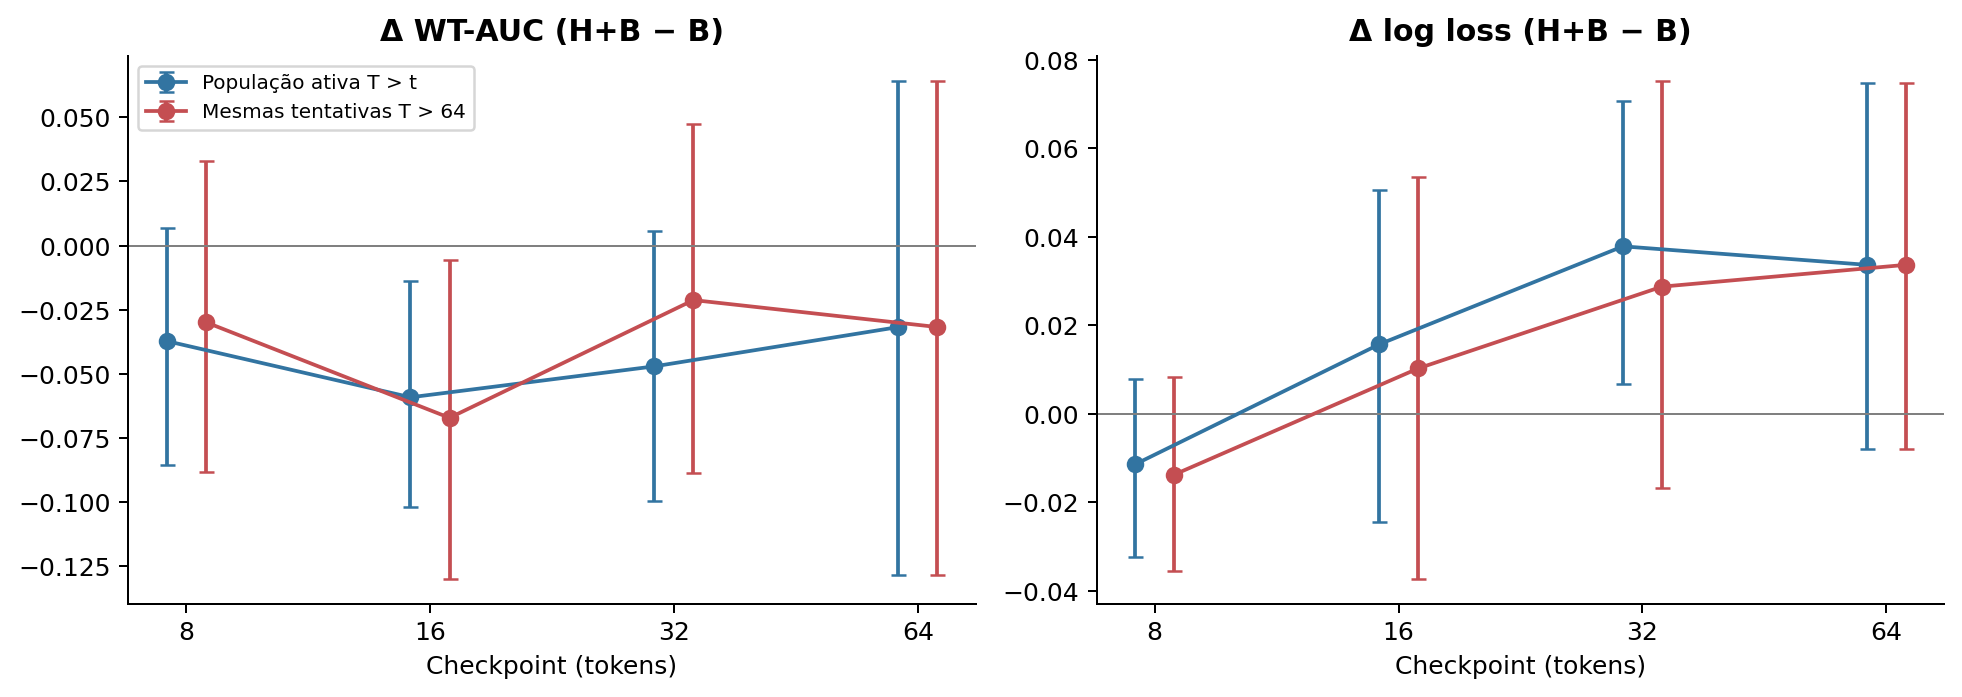

In [6]:
display(pd.json_normalize([r for r in extra["contrasts"]
    if r["checkpoint"] == "32" and r["comparison"] == "HB minus B"]))
display(extra["historical_exposure_sensitivity"])
display(Image(filename=str(SUPPLEMENT / "figures/common_cohort.png")))


### Calibração e transporte do alvo de retenção

ECE usa dez bins fixos da probabilidade da classe positiva com peso igual por
tarefa. Depende de discretização e tamanho amostral; os percentis do bootstrap
podem não conter o ECE empírico. Interprete junto a log loss e Brier.
A origem usa escores OOF; o alvo usa ajuste em toda a origem. Diferenças entre
bancos não isolam causalmente uma mudança de domínio.

Retenção usa todos os corretos ativos no gate, inclusive candidatos nunca
iniciados no replay. Cada política pode usar um checkpoint diferente.
O alvo 0,97 é empírico no desenvolvimento, sem garantia externa.


,dataset,checkpoint,predictor,tasks,attempts,bins,ece,ece_ci95,rmsce,maximum_gap
0,HumanEval+ OOF,32,B,132,2158,10,0.0445,"[0.038397960163124495, 0.09749101173074408]",0.0620,0.1271
1,HumanEval+ OOF,32,H,132,2158,10,0.0313,"[0.024596683697244656, 0.08743396985295747]",0.0754,0.9144
2,HumanEval+ OOF,32,HB,132,2158,10,0.0261,"[0.027599475551389197, 0.08413737178914867]",0.0642,0.9430
3,MBPP+ frozen,32,B,31,377,10,0.1521,"[0.0845680966755453, 0.2449376879451316]",0.1685,0.4019
4,MBPP+ frozen,32,H,31,377,10,0.1266,"[0.05625574015314315, 0.2208375370983087]",0.1387,0.7469
5,MBPP+ frozen,32,HB,31,377,10,0.1208,"[0.06482749950504924, 0.21833550664896345]",0.1341,0.8871


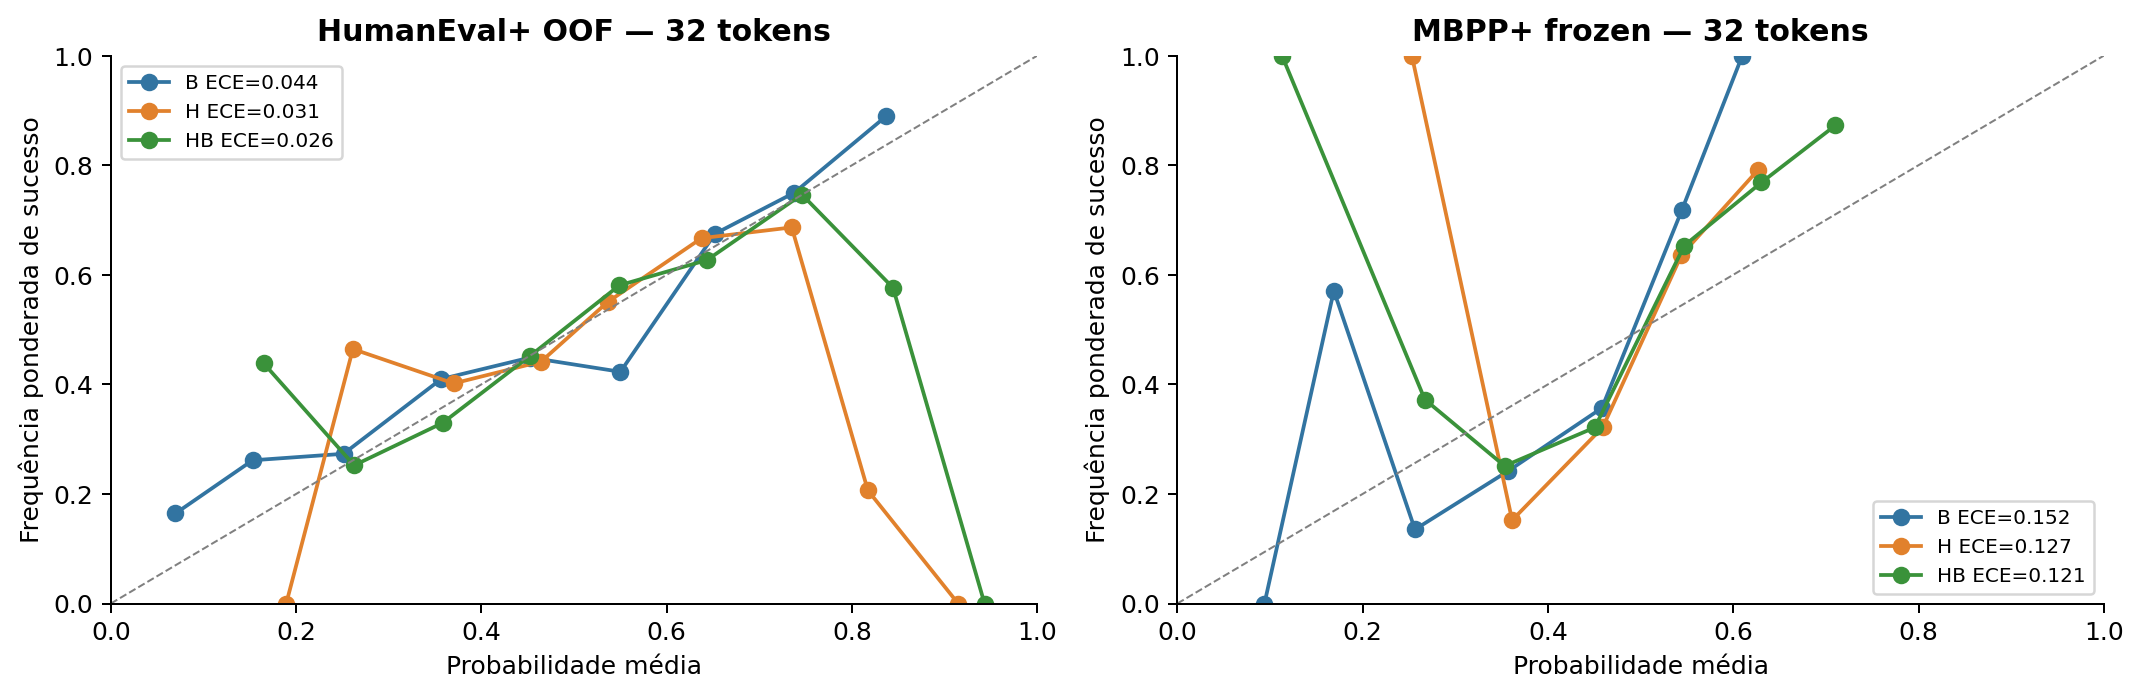

,policy,tasks,active_correct,retained_correct,recall,ci95,undefined_bootstrap_draws,dataset
0,B,132,1219,1158,0.9500,"[0.9074776873520638, 0.9825192220714608]",0,HumanEval+ OOF
1,HB,130,1079,1056,0.9787,"[0.9605702925607335, 0.9925324855117886]",0,HumanEval+ OOF
2,B,32,366,356,0.9727,"[0.9550554366565602, 0.9887656142112862]",0,MBPP+ frozen
3,HB,32,366,276,0.7541,"[0.6186639175257732, 0.8773604614495191]",0,MBPP+ frozen


,policy,fold,checkpoint,threshold,development_recall,active_correct,retained_correct,held_out_recall,dataset
0,B,0,8,0.4831,0.9758,222,221,0.9955,HumanEval+ OOF
1,HB,0,8,0.3078,0.9851,222,220,0.9910,HumanEval+ OOF
2,B,1,8,0.3192,0.9721,294,291,0.9898,HumanEval+ OOF
3,HB,1,8,0.2618,0.9761,294,282,0.9592,HumanEval+ OOF
4,B,2,32,0.2372,0.9701,196,175,0.8929,HumanEval+ OOF
5,HB,2,8,0.4236,0.9804,275,269,0.9782,HumanEval+ OOF
6,B,3,8,0.3097,0.9821,292,260,0.8904,HumanEval+ OOF
7,HB,3,64,0.3784,0.9981,133,131,0.9850,HumanEval+ OOF
8,B,4,8,0.4764,0.9705,215,211,0.9814,HumanEval+ OOF
9,HB,4,32,0.3573,0.9737,155,154,0.9935,HumanEval+ OOF


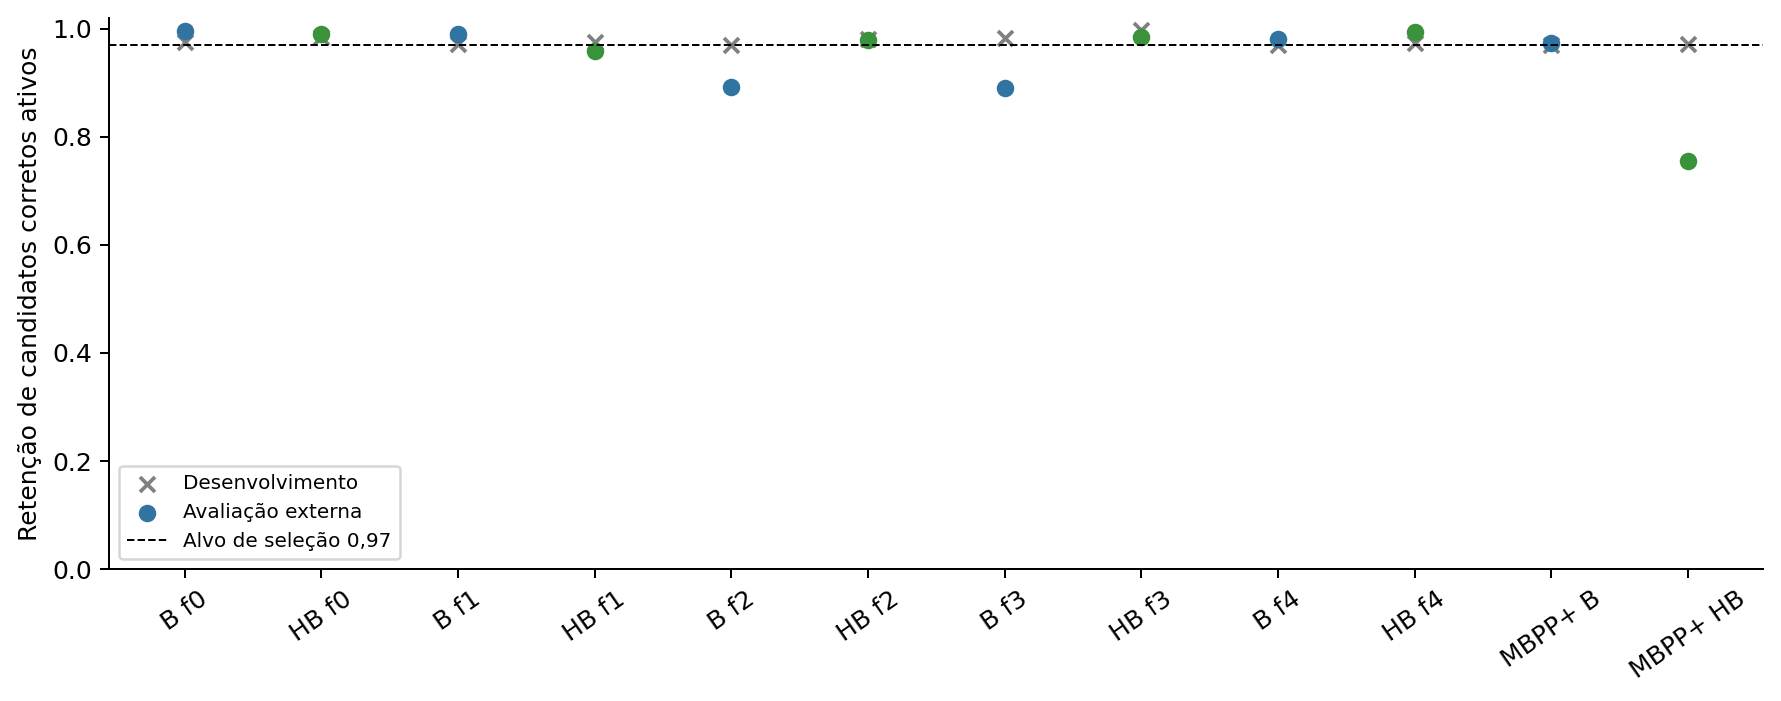

In [7]:
display(pd.DataFrame([{k: v for k, v in row.items() if k != "reliability"}
                      for row in extra["calibration"]]))
display(Image(filename=str(SUPPLEMENT / "figures/calibration_transfer.png")))
display(pd.DataFrame([dict(row, dataset=dataset)
    for dataset, item in extra["correct_retention"].items() for row in item["aggregate"]]))
display(pd.DataFrame([dict(row, dataset=dataset)
    for dataset, item in extra["correct_retention"].items() for row in item["by_fold"]]))
display(Image(filename=str(SUPPLEMENT / "figures/correct_retention.png")))


### Critérios necessários e limites da conclusão

As decisões abaixo aplicam as margens originais. Ausência de suporte ao ganho
incremental não demonstra ausência universal de sinal. Os limites dos intervalos
descrevem a precisão alcançada sob as suposições e os modelos ajustados.
Não se calcula poder observado nem se define margem de equivalência após o resultado.


In [8]:
display(pd.DataFrame(extra["decision_ledger"]))
display(Markdown((SUPPLEMENT / "README.md").read_text(encoding="utf-8")))


,criterion,estimate,ci95,boundary,direction,satisfied
0,Primary WT-AUC gain,-0.0470,"[-0.09937495818447424, 0.005583498622638421]",0.00,positive,False
1,Primary log-loss reduction,0.0379,"[0.006657260077646495, 0.07061583758815658]",0.00,negative_point,False
2,N=20 HB minus verifier: resolution_delta,-0.0152,"[-0.03787878787878788, 0.0]",-0.03,noninferiority,False
3,N=20 HB minus verifier: token_delta,-7.1818,"[-18.734848484848484, 0.8037878787878746]",0.00,negative,False
4,N=20 HB minus B: resolution_delta,0.0227,"[-0.015151515151515152, 0.06060606060606061]",-0.03,noninferiority,True
5,N=20 HB minus B: token_delta,12.9621,"[-26.335416666666667, 77.05265151515148]",0.00,negative,False
6,H2 joint criterion,NaN,NaN,NaN,NaN,False
7,Online identity replay with actual abort,NaN,NaN,NaN,NaN,True
8,Joint operational benefit,NaN,NaN,NaN,NaN,False


# Diagnósticos complementares

Análises exploratórias definidas após a conclusão e inspeção dos resultados principais.
Nenhum modelo, calibrador, limiar, rótulo, semente ou critério principal foi alterado.

## Precisão e estabilidade

| Contraste principal H+B menos B | Estimativa [IC 95%] |
|---|---|
| within_task_auc | -0.04703 [-0.09937; 0.00558] |
| log_loss | 0.03785 [0.00666; 0.07062] |

Os valores e intervalos principais foram reproduzidos a partir das probabilidades congeladas.
Os limites acima quantificam a precisão sob as suposições utilizadas. Zero no intervalo não demonstra equivalência;
log loss positivo representa maior perda de H+B. Nenhum resultado prova ausência universal de sinal.

| Métrica | Faixa da média ao excluir uma tarefa por vez |
|---|---|
| brier | [0.01449; 0.01811] |
| log_loss | [0.03247; 0.04204] |
| within_task_auc | [-0.05506; -0.03875] |

A exclusão mantém os modelos fixos. A estabilidade do sinal da estimativa não garante significância em cada exclusão.

## População constante e histórico de exposição

| Coorte em 32 tokens | Tentativas | Tarefas | ΔWT-AUC [IC 95%] | Δlog loss [IC 95%] |
|---|---:|---:|---|---|
| HumanEval+ OOF, T>64 | 1228 | 122 | -0.02121 [-0.08867; 0.04755] | 0.02875 [-0.01664; 0.07530] |
| MBPP+ frozen, T>64 | 125 | 17 | -0.02083 [-0.31250; 0.25052] | 0.00247 [-0.06472; 0.06703] |
| HumanEval+, sem as 26 tarefas históricas | 1755 | 106 | -0.03413 [-0.09255; 0.02468] | 0.01921 [-0.01571; 0.05359] |

A coorte T>64 condiciona no comprimento final. A exclusão histórica só altera a avaliação, sem retreino;
nenhuma delas substitui o endpoint ou cria uma amostra confirmatória independente.

## Retenção dos corretos

| Avaliação | Política | Corretos retidos/ativos | Retenção [IC 95%] |
|---|---|---:|---|
| HumanEval+ OOF | B | 1158/1219 | 0.94996 [0.90748; 0.98252] |
| HumanEval+ OOF | HB | 1056/1079 | 0.97868 [0.96057; 0.99253] |
| MBPP+ frozen | B | 356/366 | 0.97268 [0.95506; 0.98877] |
| MBPP+ frozen | HB | 276/366 | 0.75410 [0.61866; 0.87736] |

O denominador inclui todos os candidatos corretos ativos no gate congelado, inclusive os nunca iniciados no replay.
As políticas podem usar checkpoints diferentes; a tabela não é uma comparação pareada de retenção entre políticas.
O alvo 0,97 se refere ao desenvolvimento. Os intervalos reamostram tarefas, usando a razão das contagens somadas.

## Consequência operacional no alvo (replay offline, N=20)

| Política | Resolução | Tokens por tarefa |
|---|---:|---:|
| B | 0.84375 | 256.969 |
| HB | 0.78125 | 292.625 |
| verifier | 0.84375 | 279.906 |

| Contraste | Δresolução [IC 95%] | Δtokens [IC 95%] |
|---|---|---|
| HB minus verifier | -0.06250 [-0.15625; 0.00000] | 12.71875 [-0.59453; 34.53125] |
| HB minus B | -0.06250 [-0.15625; 0.00000] | 35.65625 [13.09219; 64.43828] |

Dados originais da transferência congelada, sem ajuste local e sem validação online MBPP+.
O sinal do contraste de tokens indica a direção do custo: valores positivos representam custo maior de H+B.

## Calibração em 32 tokens

| Avaliação | Preditor | ECE [percentis 2,5%; 97,5%] | RMSCE |
|---|---|---|---:|
| HumanEval+ OOF | B | 0.04447 [0.03840; 0.09749] | 0.06203 |
| HumanEval+ OOF | H | 0.03130 [0.02460; 0.08743] | 0.07540 |
| HumanEval+ OOF | HB | 0.02606 [0.02760; 0.08414] | 0.06420 |
| MBPP+ frozen | B | 0.15214 [0.08457; 0.24494] | 0.16853 |
| MBPP+ frozen | H | 0.12660 [0.05626; 0.22084] | 0.13874 |
| MBPP+ frozen | HB | 0.12082 [0.06483; 0.21834] | 0.13406 |

Dez bins fixos de probabilidade da classe positiva, cada tarefa com o mesmo peso total.
ECE é diagnóstico dependente de discretização e tamanho amostral; não substitui log loss ou Brier.
ECE menor isoladamente não implica melhor predição ou política operacional.
O bootstrap percentil de ECE pode ter viés positivo e não conter a estimativa empírica.
A origem usa escores OOF e o alvo um modelo ajustado em toda a origem; diferenças entre bancos não isolam um efeito causal de domínio.

## Critérios de decisão preservados

| Critério | Estimativa [IC 95%] | Condição | Atendido |
|---|---|---|---|
| Primary WT-AUC gain | -0.04703 [-0.09937; 0.00558] | limite inferior > 0 | não |
| Primary log-loss reduction | 0.03785 [0.00666; 0.07062] | estimativa < 0 | não |
| N=20 HB minus verifier: resolution_delta | -0.01515 [-0.03788; 0.00000] | limite inferior > -0.03 | não |
| N=20 HB minus verifier: token_delta | -7.18182 [-18.73485; 0.80379] | limite superior < 0 | não |
| N=20 HB minus B: resolution_delta | 0.02273 [-0.01515; 0.06061] | limite inferior > -0.03 | sim |
| N=20 HB minus B: token_delta | 12.96212 [-26.33542; 77.05265] | limite superior < 0 | não |
| H2 joint criterion | — | regra conjunta | não |
| Online identity replay with actual abort | — | regra conjunta | sim |
| Joint operational benefit | — | regra conjunta | não |

## Reprodução e limites

```powershell
.venv/Scripts/python.exe scripts/analyze_research_robustness.py
```

Bootstrap: 2000 reamostragens de tarefas, seed 20260921.
Todos os intervalos adicionais são pontuais e exploratórios, condicionais aos modelos já ajustados.
Folds compartilham dados de treinamento e não são replicações independentes.
Identidades, hashes dos insumos e parâmetros estão em [results.json](results.json).
Tabelas por tarefa, fold e bin estão nos CSV; figuras são exportadas em PNG, SVG e PDF.

Referências metodológicas: [Guo et al. (2017)](https://proceedings.mlr.press/v70/guo17a.html),
[Greenland et al. (2016)](https://doi.org/10.1007/s10654-016-0149-3).


## Aprofundamento científico executado em 17/10/2026

As famílias abaixo foram definidas depois de conhecer os resultados originais.
Todas usam as mesmas tarefas externas originais. A seleção, o PCA e a calibração
respeitam as partições internas; o residual exclui os rótulos pontuados também
na seleção e calibração do primeiro estágio. Os intervalos adicionais são
pontuais e condicionais, sem confirmação independente ou cobertura simultânea.


,family,roc_auc,pr_auc,log_loss,brier,within_task_auc,delta_wt_auc_vs_B,delta_log_loss_vs_B
0,B_original,0.7005,0.7197,0.6302,0.2199,0.6282,"{'estimate': 0.0, 'ci95': [0.0, 0.0], 'tasks':...","{'estimate': 0.0, 'ci95': [0.0, 0.0], 'tasks':..."
1,B_reproduced,0.7005,0.7197,0.6302,0.2199,0.6282,"{'estimate': 0.0, 'ci95': [0.0, 0.0], 'tasks':...","{'estimate': -1.9985923673402422e-18, 'ci95': ..."
2,HB_original,0.6456,0.6231,0.6681,0.2362,0.5811,"{'estimate': -0.04702865751183576, 'ci95': [-0...","{'estimate': 0.037850604885218846, 'ci95': [0...."
3,HB_pca16,0.6988,0.7104,0.6334,0.2209,0.6240,"{'estimate': -0.0041706562343172245, 'ci95': [...","{'estimate': 0.0031602678129271423, 'ci95': [-..."
4,HB_pca64,0.6962,0.6903,0.6318,0.2208,0.6298,"{'estimate': 0.0015958999014003086, 'ci95': [-...","{'estimate': 0.0015797865404947049, 'ci95': [-..."
5,HB_stronger,0.6052,0.6080,0.6764,0.2411,0.5476,"{'estimate': -0.08057523001021452, 'ci95': [-0...","{'estimate': 0.046164058321633866, 'ci95': [0...."
6,H_original,0.5924,0.5837,0.6869,0.2460,0.5681,"{'estimate': -0.06004633395733728, 'ci95': [-0...","{'estimate': 0.056649559883984964, 'ci95': [0...."
7,H_residual_B,0.7020,0.7211,0.6289,0.2194,0.6345,"{'estimate': 0.006372471702218307, 'ci95': [-0...","{'estimate': -0.0012688235404824447, 'ci95': [..."
8,confidence_only,0.6971,0.6975,0.6316,0.2207,0.6242,"{'estimate': -0.003970782811243335, 'ci95': [-...","{'estimate': 0.0013415759657086895, 'ci95': [-..."
9,entropy_pair,0.6999,0.7110,0.6307,0.2201,0.6036,"{'estimate': -0.02459432591688783, 'ci95': [-0...","{'estimate': 0.0004547620305143074, 'ci95': [-..."


,family,delta_wt_auc_vs_original_HB,delta_log_loss_vs_original_HB
0,HB_stronger,"{'estimate': -0.03354657249837877, 'ci95': [-0...","{'estimate': 0.00831345343641502, 'ci95': [-0...."
1,HB_pca16,"{'estimate': 0.042858001277518536, 'ci95': [-0...","{'estimate': -0.03469033707229169, 'ci95': [-0..."
2,HB_pca64,"{'estimate': 0.04862455741323607, 'ci95': [0.0...","{'estimate': -0.03627081834472414, 'ci95': [-0..."
3,H_residual_B,"{'estimate': 0.053401129214054065, 'ci95': [0....","{'estimate': -0.039119428425701284, 'ci95': [-..."


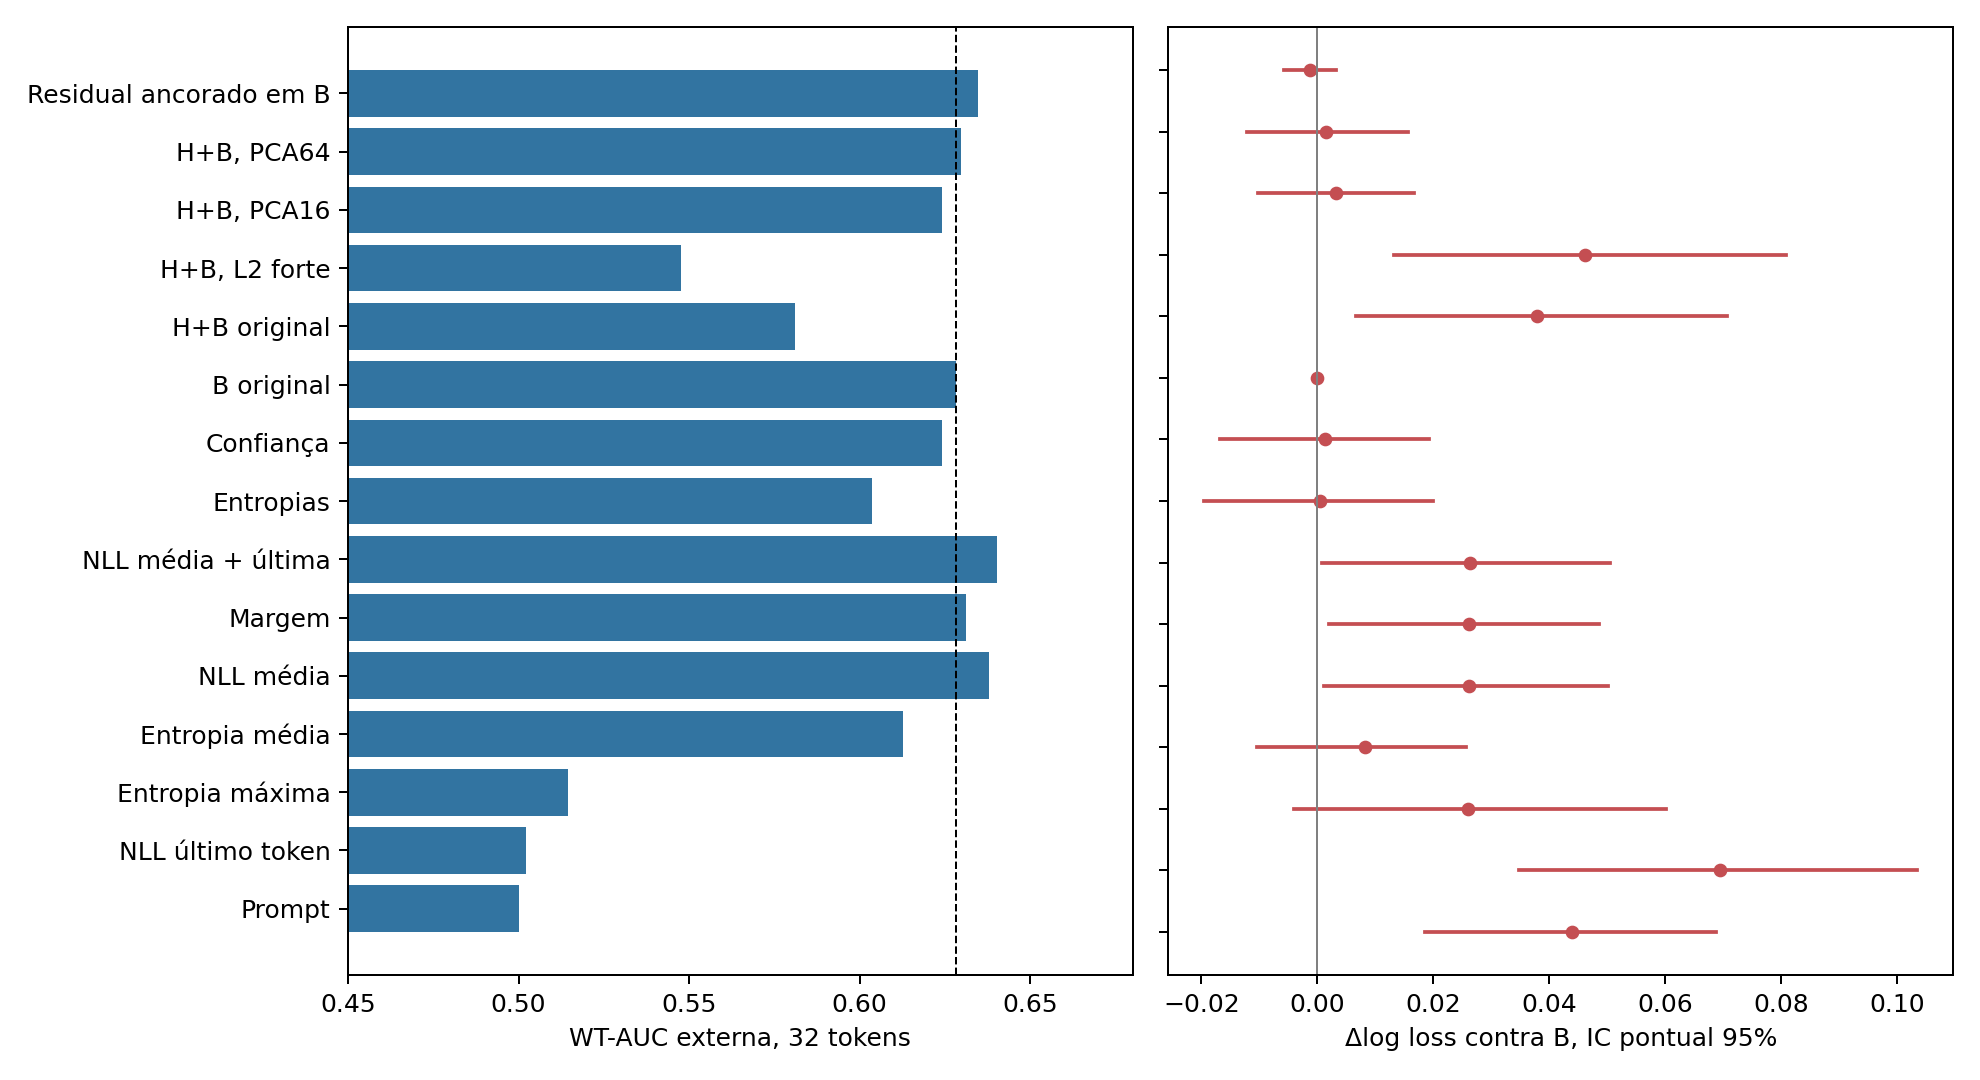

PCA e residual reduzem a desvantagem original, sem demonstrar ganho sobre B. A regularização conjunta mais forte não resolveu a desvantagem na grade testada.

In [9]:
exc = evidence["excellence"]
EXCELLENCE = ROOT / "reports/excellence"
display(pd.DataFrame(exc["models"]))
display(pd.DataFrame(exc["recovery_vs_original_HB"]))
display(Image(filename=str(EXCELLENCE / "figures/model_ablation.png")))
display(Markdown("PCA e residual reduzem a desvantagem original, sem demonstrar ganho sobre B. "
                 "A regularização conjunta mais forte não resolveu a desvantagem na grade testada."))


,fold,layer,dimension,training_tasks,training_candidates,variance_top16,variance_top64,variance_top128
0,0,6,1536,105,1706,0.3897,0.7000,0.8461
1,0,13,1536,105,1706,0.3694,0.6594,0.8073
2,0,20,1536,105,1706,0.3668,0.6371,0.7820
3,0,27,1536,105,1706,0.4130,0.6582,0.7886
4,1,6,1536,105,1694,0.3992,0.7092,0.8519
5,1,13,1536,105,1694,0.3790,0.6707,0.8142
6,1,20,1536,105,1694,0.3705,0.6434,0.7868
7,1,27,1536,105,1694,0.4166,0.6621,0.7928
8,2,6,1536,106,1776,0.3937,0.7011,0.8446
9,2,13,1536,106,1776,0.3725,0.6621,0.8067


,fold_a,fold_b,layer,cosine_raw_coordinates,scope
0,0,1,13,0.7158,Same layer only; overlapping training tasks; n...
1,0,3,13,0.7242,Same layer only; overlapping training tasks; n...
2,1,3,13,0.7455,Same layer only; overlapping training tasks; n...


,fraction,family,training_task_range,roc_auc,pr_auc,log_loss,brier,within_task_auc,within_task_auc_interval
0,0.3,B_fixed_C01,"[32, 32]",0.6963,0.7156,0.6409,0.2243,0.6308,"{'estimate': 0.6307995596677936, 'ci95': [0.58..."
1,0.3,HB_PCA16_fixed_layer13_C01,"[32, 32]",0.6903,0.7155,0.6477,0.2272,0.6368,"{'estimate': 0.6368389395034447, 'ci95': [0.59..."
2,0.6,B_fixed_C01,"[63, 64]",0.6744,0.6801,0.6454,0.2269,0.6271,"{'estimate': 0.6271377886153702, 'ci95': [0.58..."
3,0.6,HB_PCA16_fixed_layer13_C01,"[63, 64]",0.6843,0.6887,0.6419,0.2250,0.6395,"{'estimate': 0.6394961744663189, 'ci95': [0.59..."
4,1.0,B_fixed_C01,"[105, 106]",0.6982,0.7091,0.6320,0.2209,0.6262,"{'estimate': 0.626194624782349, 'ci95': [0.581..."
5,1.0,HB_PCA16_fixed_layer13_C01,"[105, 106]",0.7011,0.7146,0.6306,0.2204,0.6214,"{'estimate': 0.6214456231265463, 'ci95': [0.57..."


,dataset,checkpoint,tasks,mixed_tasks,single_prefix_tasks,mixed_single_prefix_tasks,mean_fraction_unavoidably_tied_pairs,constant_score_checks_passed
0,HumanEval+,8,132,100,16,15,0.6385,True
1,HumanEval+,16,132,97,0,0,0.1545,True
2,HumanEval+,32,132,92,2,0,0.0532,True
3,HumanEval+,64,122,69,13,0,0.0604,True
4,MBPP+,8,32,24,5,3,0.4246,True
5,MBPP+,16,32,24,0,0,0.0486,True
6,MBPP+,32,31,18,4,0,0.0000,True
7,MBPP+,64,17,6,2,0,0.0000,True


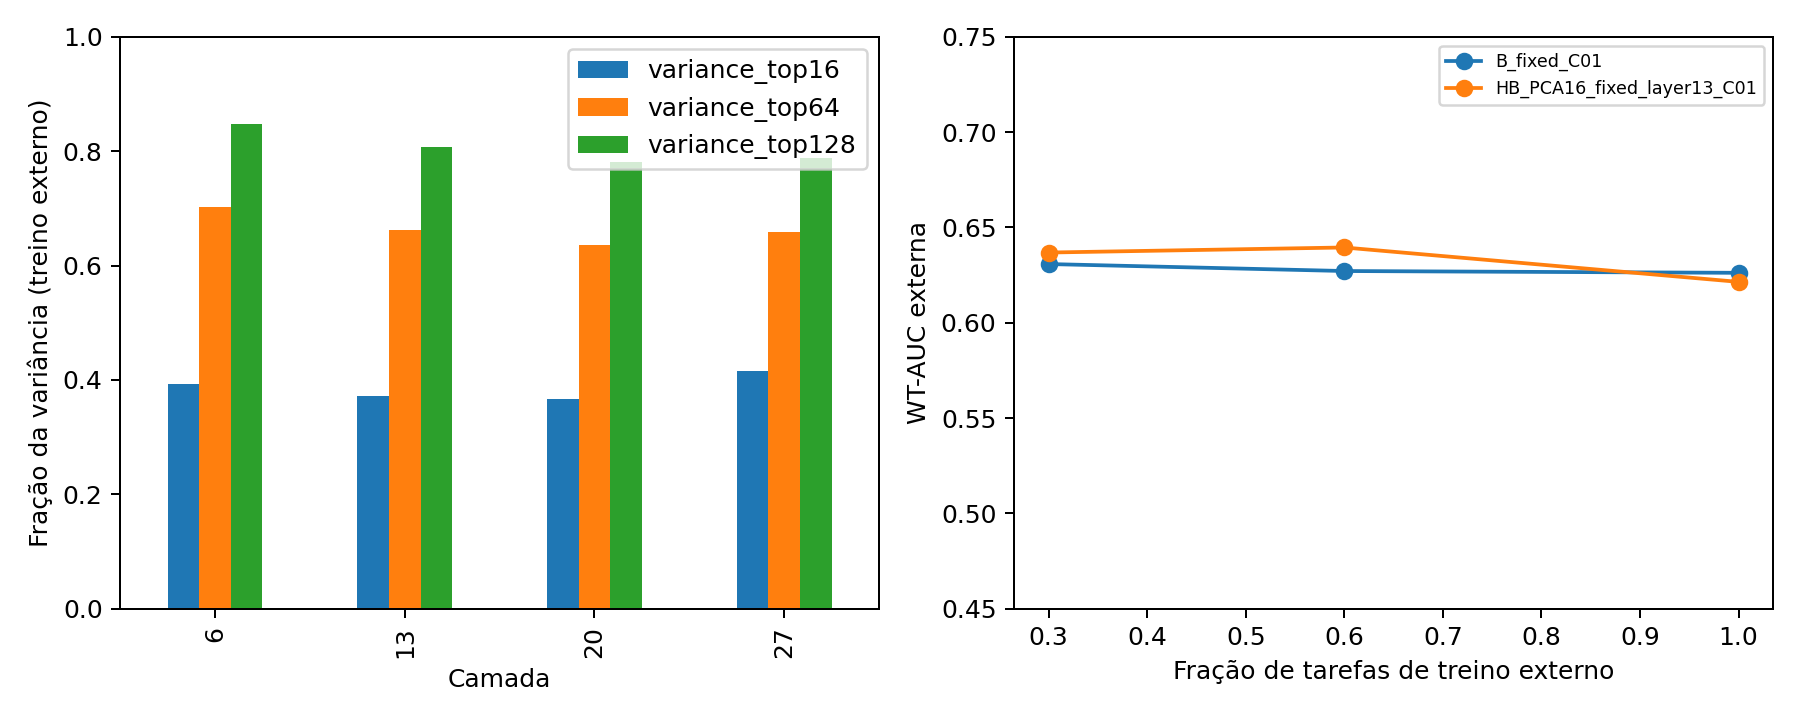

PCA foi ajustado no treino externo. A curva de tarefas usa algoritmos fixos; não estima a curva do procedimento original selecionado nem identifica causalidade.

In [10]:
display(pd.DataFrame(exc["geometry"]["training_spectra"]))
display(pd.DataFrame(exc["geometry"]["same_layer_direction_cosines"]))
display(pd.DataFrame(exc["geometry"]["learning_curves"]))
display(pd.DataFrame(exc["prefix_diagnostics"]["summaries"]))
display(Image(filename=str(EXCELLENCE / "geometry/geometry_learning.png")))
display(Markdown("PCA foi ajustado no treino externo. A curva de tarefas usa algoritmos fixos; "
                 "não estima a curva do procedimento original selecionado nem identifica causalidade."))


,dataset,family,false_aborts_all_correct,tasks_with_false_aborts,share_in_top_five_tasks
0,source_OOF_external,B,121,26,0.5372
1,source_OOF_external,HB,15,8,0.8000
2,source_development_not_external,B,38,19,0.5000
3,source_development_not_external,HB,37,10,0.8649
4,target_frozen_external,B,10,8,0.7000
5,target_frozen_external,HB,90,12,0.6667


,task_id,family,verifier_resolved,gate_resolved,lost_task,verifier_started,gate_started,started_correct,started_active_correct,started_correct_false_aborts
0,Mbpp/772,B,1,1,False,1,1,1,1,0
1,Mbpp/111,B,1,1,False,3,4,2,2,1
2,Mbpp/285,B,1,1,False,1,1,1,1,0
3,Mbpp/123,B,0,0,False,20,20,0,0,0
4,Mbpp/569,B,1,1,False,1,1,1,1,0
...,...,...,...,...,...,...,...,...,...,...
59,Mbpp/65,HB,1,1,False,1,1,1,1,0
60,Mbpp/100,HB,1,1,False,3,3,1,1,0
61,Mbpp/92,HB,0,0,False,20,20,0,0,0
62,Mbpp/276,HB,1,1,False,1,1,1,1,0


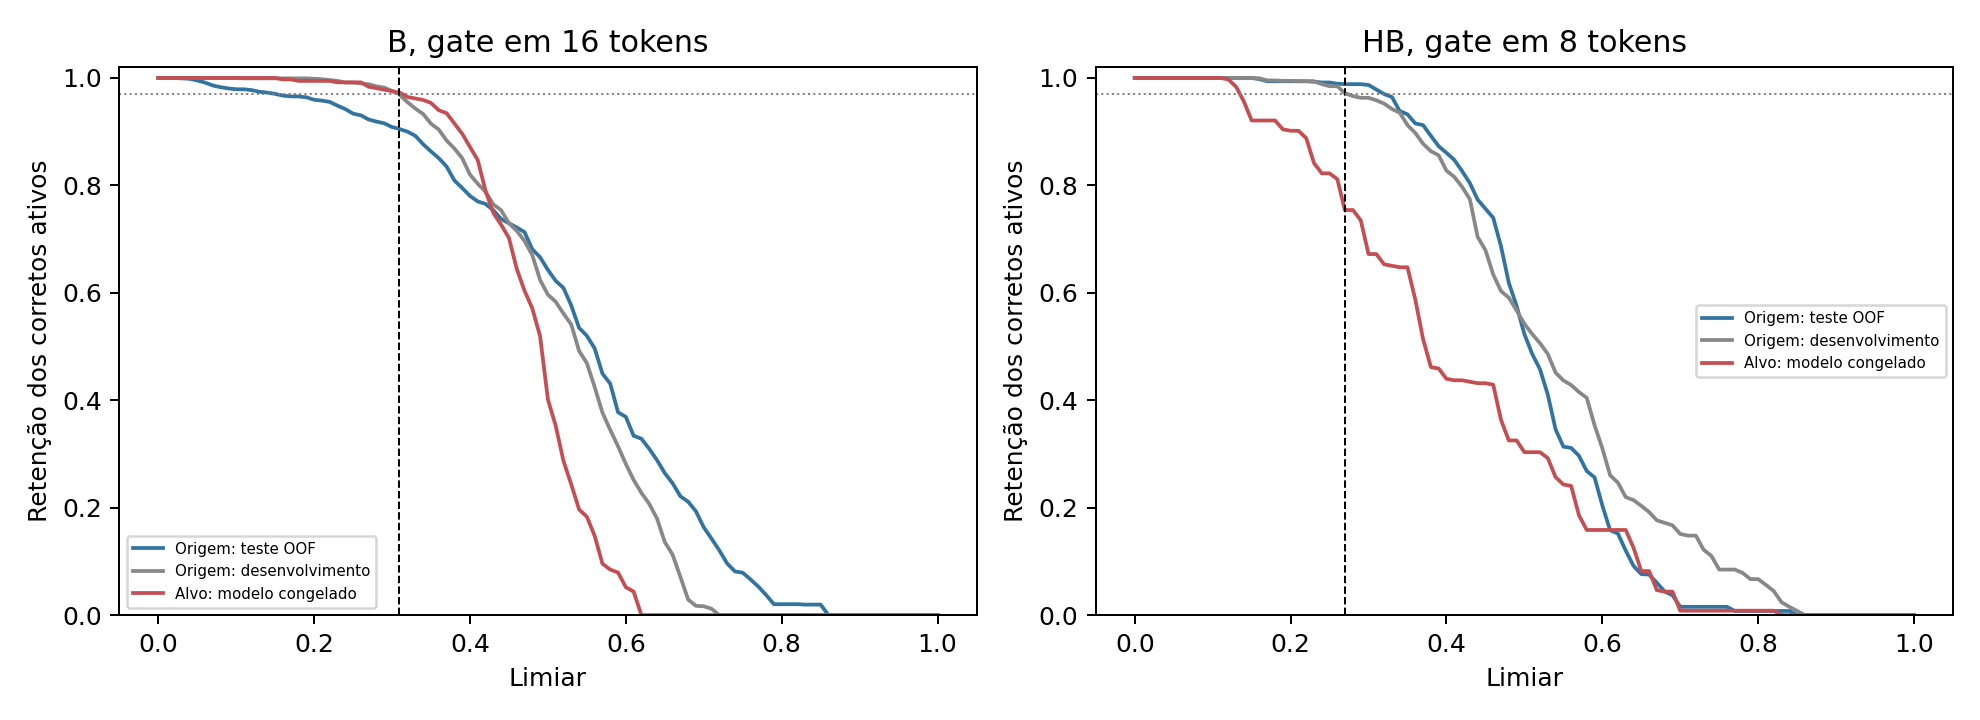

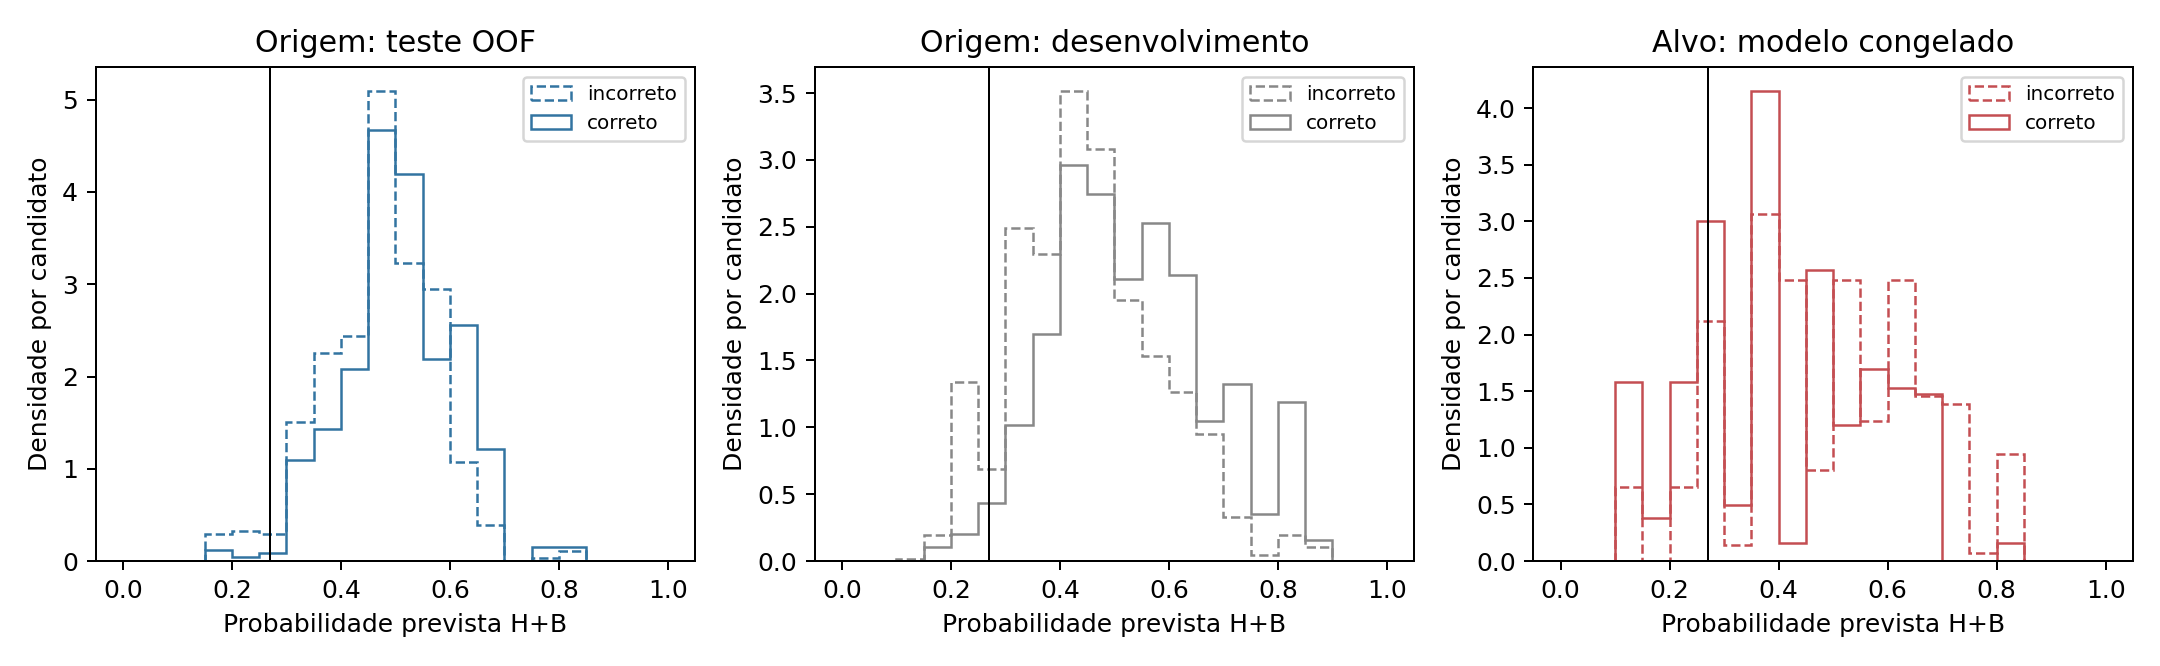

Origem OOF, desenvolvimento da origem e alvo congelado são avaliações distintas. As curvas no alvo não escolhem um novo limiar.

In [11]:
display(pd.DataFrame(exc["transfer"]["false_abort_concentration"]))
display(pd.DataFrame(exc["transfer"]["target_coverage"]))
display(Image(filename=str(EXCELLENCE / "transfer/retention_curves.png")))
display(Image(filename=str(EXCELLENCE / "transfer/conditional_scores.png")))
display(Markdown("Origem OOF, desenvolvimento da origem e alvo congelado são avaliações distintas. "
                 "As curvas no alvo não escolhem um novo limiar."))


,dataset,checkpoint,budget,policy,tasks,resolution,...,active_correct_retention_all_candidates,false_abort_rate_started_active_correct,saving_vs_verifier,delta_tokens_vs_verifier,delta_resolution_vs_verifier,tokens_minus_oracle
0,HumanEval+,8,20,oracle,132,0.8485,...,1.0,0.0,"{'estimate': 0.7774805881113327, 'ci95': [0.70...","{'estimate': -363.3484848484849, 'ci95': [-491...","{'estimate': 0.0, 'ci95': [0.0, 0.0], 'tasks':...",0.0
1,HumanEval+,16,20,oracle,132,0.8485,...,1.0,0.0,"{'estimate': 0.6970448540258393, 'ci95': [0.61...","{'estimate': -325.75757575757575, 'ci95': [-44...","{'estimate': 0.0, 'ci95': [0.0, 0.0], 'tasks':...",0.0
2,HumanEval+,32,20,oracle,132,0.8485,...,1.0,0.0,"{'estimate': 0.544764868939357, 'ci95': [0.446...","{'estimate': -254.5909090909091, 'ci95': [-365...","{'estimate': 0.0, 'ci95': [0.0, 0.0], 'tasks':...",0.0
3,HumanEval+,64,20,oracle,132,0.8485,...,1.0,0.0,"{'estimate': 0.34106566810938743, 'ci95': [0.2...","{'estimate': -159.3939393939394, 'ci95': [-250...","{'estimate': 0.0, 'ci95': [0.0, 0.0], 'tasks':...",0.0
4,MBPP+,8,20,oracle,32,0.8438,...,1.0,0.0,"{'estimate': 0.7625320978006029, 'ci95': [0.57...","{'estimate': -213.4375, 'ci95': [-397.94609375...","{'estimate': 0.0, 'ci95': [0.0, 0.0], 'tasks':...",0.0
5,MBPP+,16,20,oracle,32,0.8438,...,1.0,0.0,"{'estimate': 0.6499944177738082, 'ci95': [0.45...","{'estimate': -181.9375, 'ci95': [-348.19765625...","{'estimate': 0.0, 'ci95': [0.0, 0.0], 'tasks':...",0.0
6,MBPP+,32,20,oracle,32,0.8438,...,1.0,0.0,"{'estimate': 0.4425588924863235, 'ci95': [0.23...","{'estimate': -123.875, 'ci95': [-260.04375, -3...","{'estimate': 0.0, 'ci95': [0.0, 0.0], 'tasks':...",0.0
7,MBPP+,64,20,oracle,32,0.8438,...,1.0,0.0,"{'estimate': 0.18756280004465786, 'ci95': [0.0...","{'estimate': -52.5, 'ci95': [-129.0625, -7.999...","{'estimate': 0.0, 'ci95': [0.0, 0.0], 'tasks':...",0.0


,dataset,share_oracle_saving_from_unresolved_tasks,share_verifier_tokens_in_unresolved_tasks
0,HumanEval+,0.7144,0.6073
1,MBPP+,0.8612,0.7460


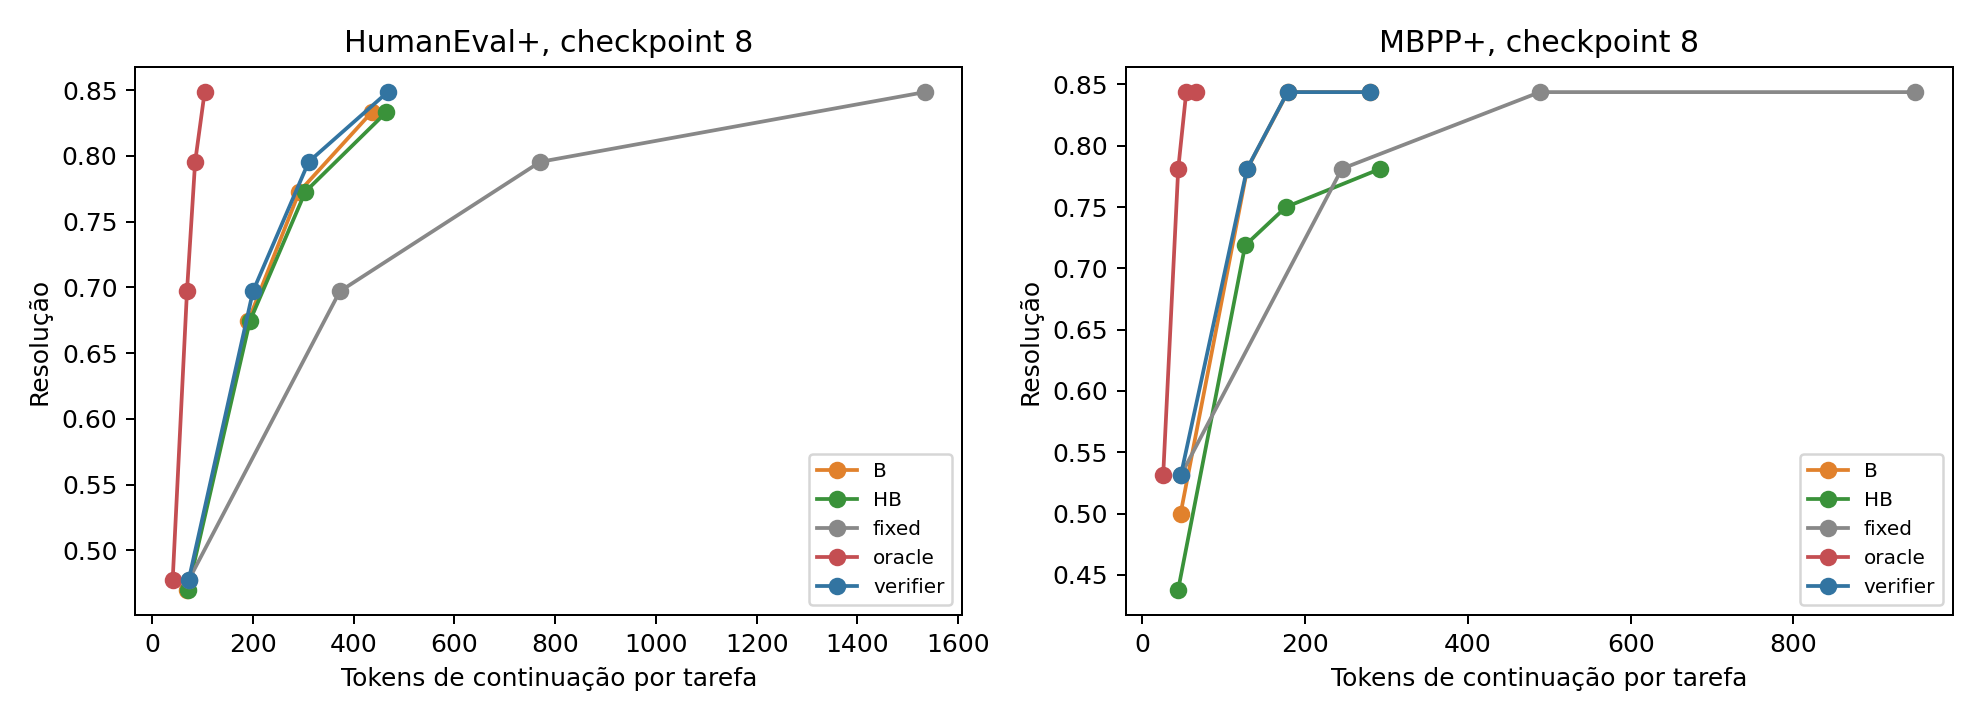

O oracle conhece os rótulos e preserva todos os corretos; não é uma política online nem um limite inferior universal para políticas que podem descartar sucessos.

{'status': 'completed',
 'created_at': '2026-10-17T06:27:55.204931+00:00',
 'pairs': 50,
 'trajectories_generated': 100,
 'tasks': 26,
 'hardware': {'device': 'NVIDIA GeForce RTX 3050 6GB Laptop GPU',
  'memory_total_mib': 6143.5,
  'peak_allocated_mib': 4085.0,
  'peak_reserved_mib': 4978.0,
  'cuda': '12.6',
  'driver_version': '576.52',
  'weight_storage_dtype': 'bfloat16',
  'linear_compute_dtype': 'float32',
  'python': '3.12.8',
  'torch': '2.12.0+cu126',
  'bf16_supported': True,
  'requested_gpu': 'RTX 4060',
  'requested_gpu_present': False},
 'all_exact_tokens_and_states': True,
 'timing_scope': 'Instrumented paired capture implementation benchmark, not a claim of policy latency savings',
 'mean_original_seconds': 8.764331248002708,
 'mean_selective_seconds': 8.47500416399911,
 'mean_tokens': 74.36,
 'mean_historical_verification_seconds': 0.10516764319998799}

,main_tasks,technical_tasks,attempts,expected_hours,hours_with_50pct_buffer
0,100,20,2400,3.8075,5.7112
1,120,20,2800,4.4420,6.6630


A extensão independente aguarda aprovação do estudante e revisão do orientador. Nenhuma trajetória da nova amostra foi coletada.

In [12]:
oracle = [r for r in exc["economics"]["summaries"] if r["policy"] == "oracle" and r["budget"] == 20]
display(pd.DataFrame(oracle))
display(pd.DataFrame(exc["oracle_concentration"]))
display(Image(filename=str(EXCELLENCE / "economics/oracle_frontier.png")))
display(Markdown("O oracle conhece os rótulos e preserva todos os corretos; não é uma política online "
                 "nem um limite inferior universal para políticas que podem descartar sucessos."))
display(exc["hardware"])
display(pd.DataFrame(json.loads((EXCELLENCE / "resource_budget.json").read_text())["scenarios"]))
display(Markdown("A extensão independente aguarda aprovação do estudante e revisão do orientador. "
                 "Nenhuma trajetória da nova amostra foi coletada."))


## 1. O que já pode ser afirmado

A primeira comparação usa as mesmas 150 tentativas históricas de 30 tarefas,
com o verificador local original. Não misturamos esses rótulos com HumanEval+.
O orçamento N é o máximo de tentativas; resolução é a fração de tarefas com pelo
menos um sucesso no prefixo de N candidatos, na ordem armazenada.


,budget,tasks,solved,resolution,resolution_ci95,fixed_tokens,verifier_tokens,token_saving_fraction
0,1,30,17,0.5667,"[0.4, 0.7333333333333333]",1637,1637,0.0000
1,2,30,22,0.7333,"[0.5666666666666667, 0.9]",3158,2336,0.2603
2,3,30,24,0.8000,"[0.6666666666666666, 0.9333333333333333]",5031,3166,0.3707
3,4,30,24,0.8000,"[0.6666666666666666, 0.9333333333333333]",6630,3639,0.4511
4,5,30,25,0.8333,"[0.7, 0.9666666666666667]",8149,4029,0.5056


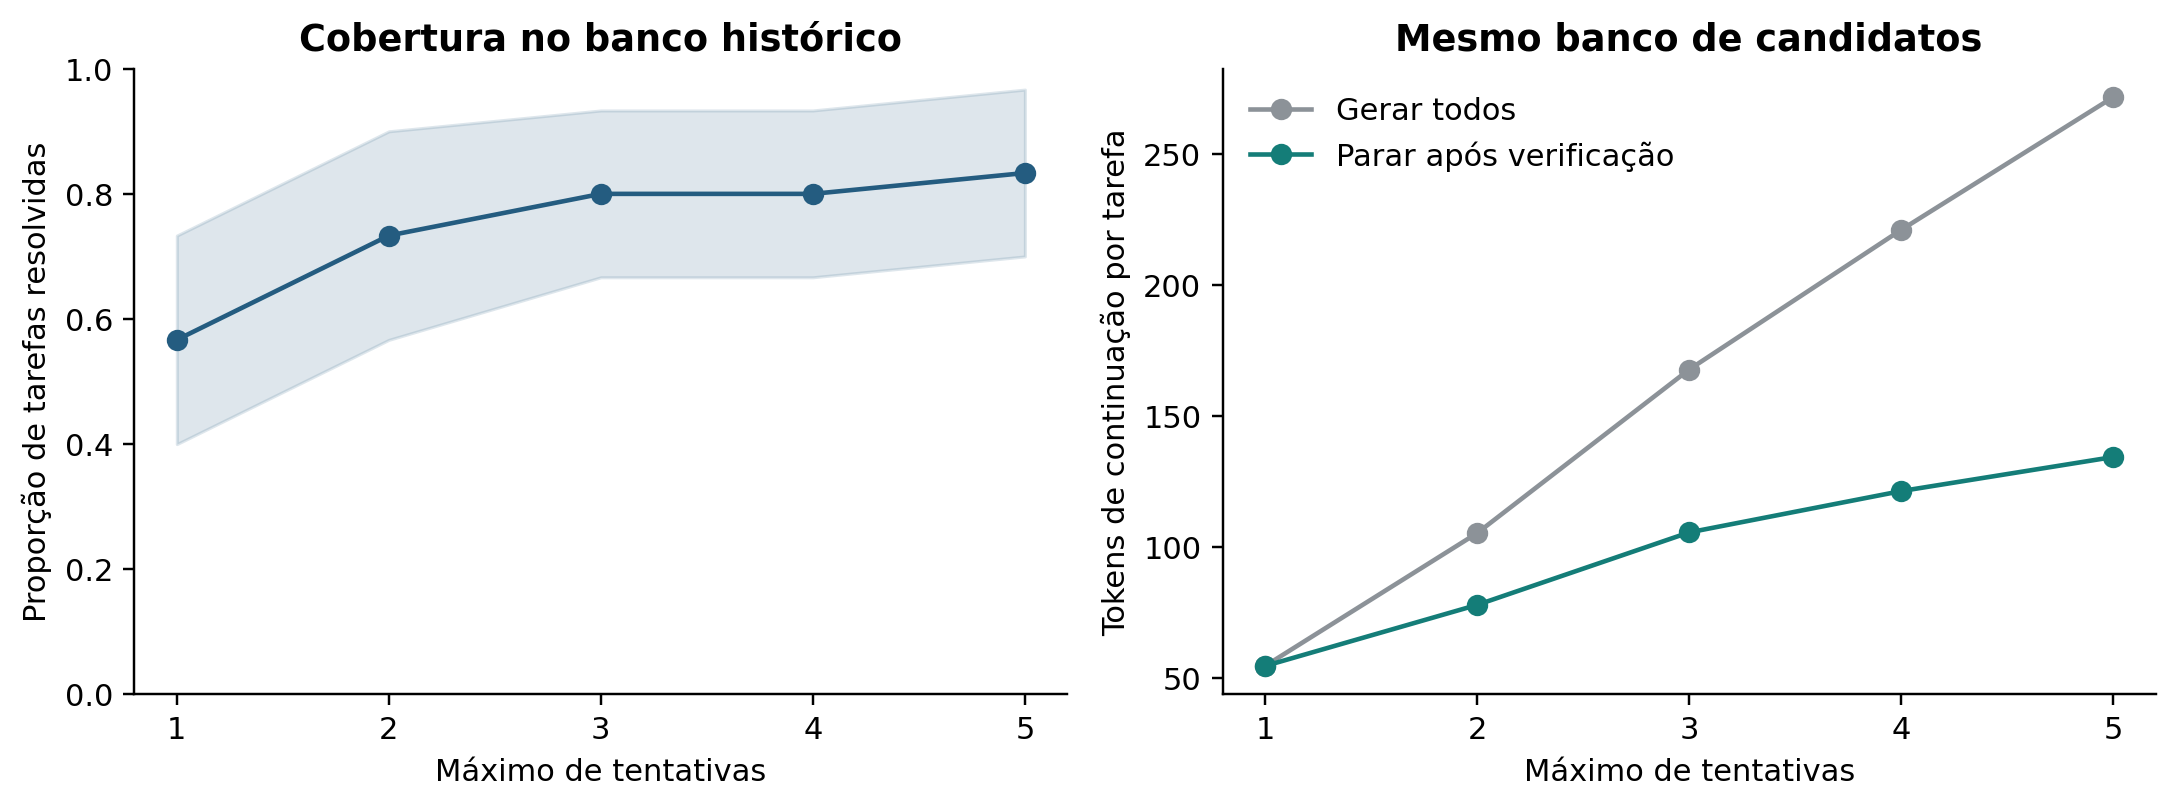

Com N=1, foram resolvidas **17/30** tarefas; com N=5, **25/30**. Gerar todos os candidatos consumiu **8,149 tokens**; parar após aprovação consumiria **4,029 tokens** no mesmo banco, uma redução de **50.56%**. Essa economia é atribuível ao verificador. Não mede aborto de um candidato ainda incompleto nem economia de tempo online.

In [13]:
sampling = pd.DataFrame(evidence["legacy_sampling"])
display(sampling[["budget", "tasks", "solved", "resolution", "resolution_ci95", "fixed_tokens", "verifier_tokens", "token_saving_fraction"]])
display(Image(filename=str(REPORT / "figures/legacy_sampling.png")))
first, last = evidence["legacy_sampling"][0], evidence["legacy_sampling"][-1]
display(Markdown(f"Com N=1, foram resolvidas **{first['solved']}/{first['tasks']}** tarefas; "
                f"com N=5, **{last['solved']}/{last['tasks']}**. Gerar todos os candidatos consumiu "
                f"**{last['fixed_tokens']:,} tokens**; parar após aprovação consumiria "
                f"**{last['verifier_tokens']:,} tokens** no mesmo banco, uma redução de "
                f"**{100*last['token_saving_fraction']:.2f}%**. Essa economia é atribuível ao verificador. "
                "Não mede aborto de um candidato ainda incompleto nem economia de tempo online."))


## 2. Quantas tarefas sustentam a discriminação intratarefa?

Uma tarefa com todos os candidatos corretos ou todos incorretos não permite
calcular AUC intratarefa. Ela continua contribuindo para perdas probabilísticas
e métricas de resolução. As categorias abaixo descrevem cinco tentativas observadas;
não significam que a probabilidade verdadeira seja zero ou um.


,tarefas,tentativas,acertos
category,,,
all_correct,9,45,45
all_failed,5,25,0
mixed,16,80,43


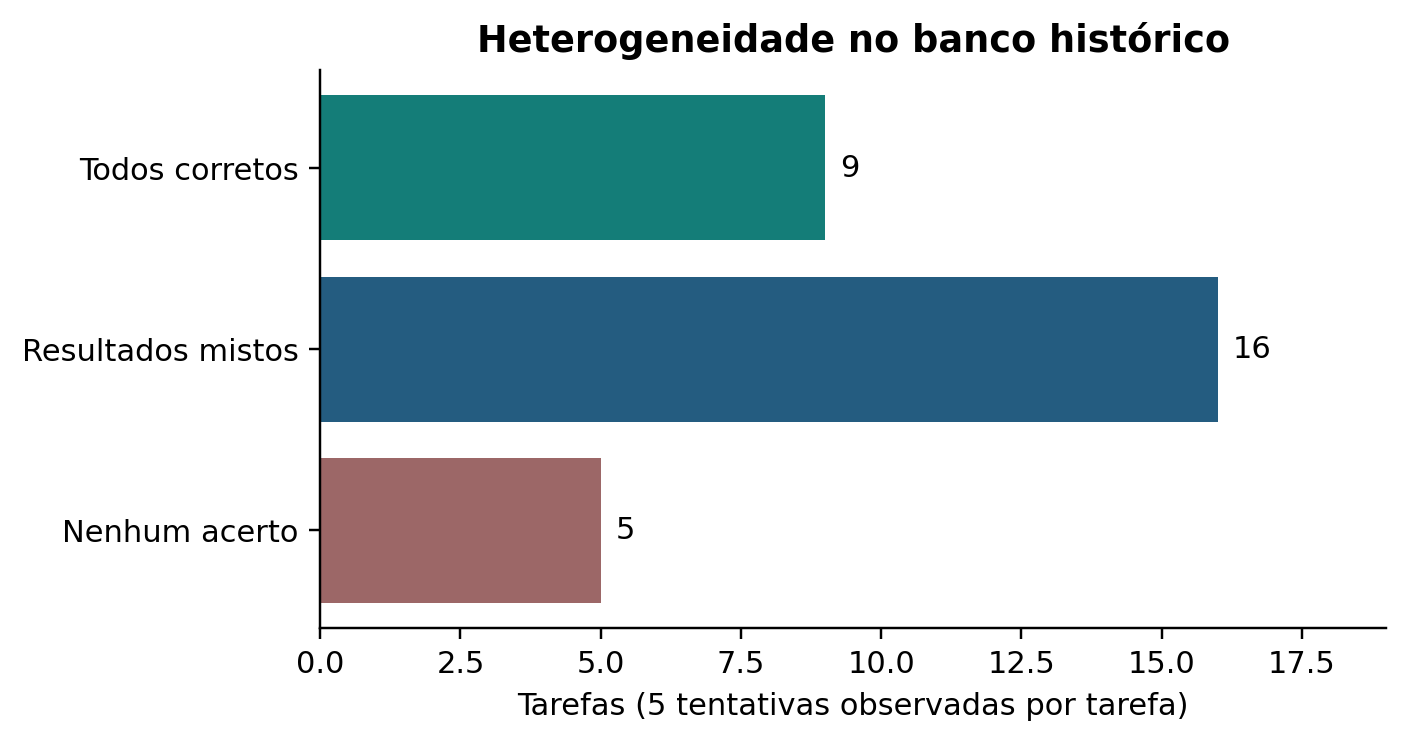

In [14]:
composition = pd.DataFrame(evidence["legacy_task_composition"])
display(composition.groupby("category").agg(tarefas=("task_id", "size"), tentativas=("attempts", "sum"), acertos=("correct", "sum")))
display(Image(filename=str(REPORT / "figures/legacy_task_composition.png")))


## 3. Reanálise exploratória dos estados finais

Cinco folds externos por tarefa, três internos para selecionar camada e regularização.
O resultado avalia o procedimento de seleção. Não usamos a melhor camada encontrada
no teste como resultado final. Os estados históricos foram retokenizados e não
dispõem da validação causal da nova coleta.

- **B tardio:** log(1 + comprimento do prompt) e log(1 + comprimento final).
- **H final:** representação no último token da resposta.
- **H+B tardio:** concatenação das duas fontes.

O comprimento final é permitido nesta análise tardia; seria vazamento em uma
política precoce. Portanto, esta comparação não é o endpoint H+B versus B em 32 tokens.


,family,roc_auc,within_task_auc,log_loss,brier,mixed_tasks,WT-AUC IC95%
0,B_late,0.5565,0.8229,0.6571,0.2325,16,"[0.6666666666666666, 0.9479166666666666]"
1,H_final,0.7806,0.8438,0.5144,0.1695,16,"[0.7083333333333334, 0.9479166666666667]"
2,HB_late,0.7824,0.8438,0.5138,0.1693,16,"[0.7083333333333334, 0.9479166666666667]"


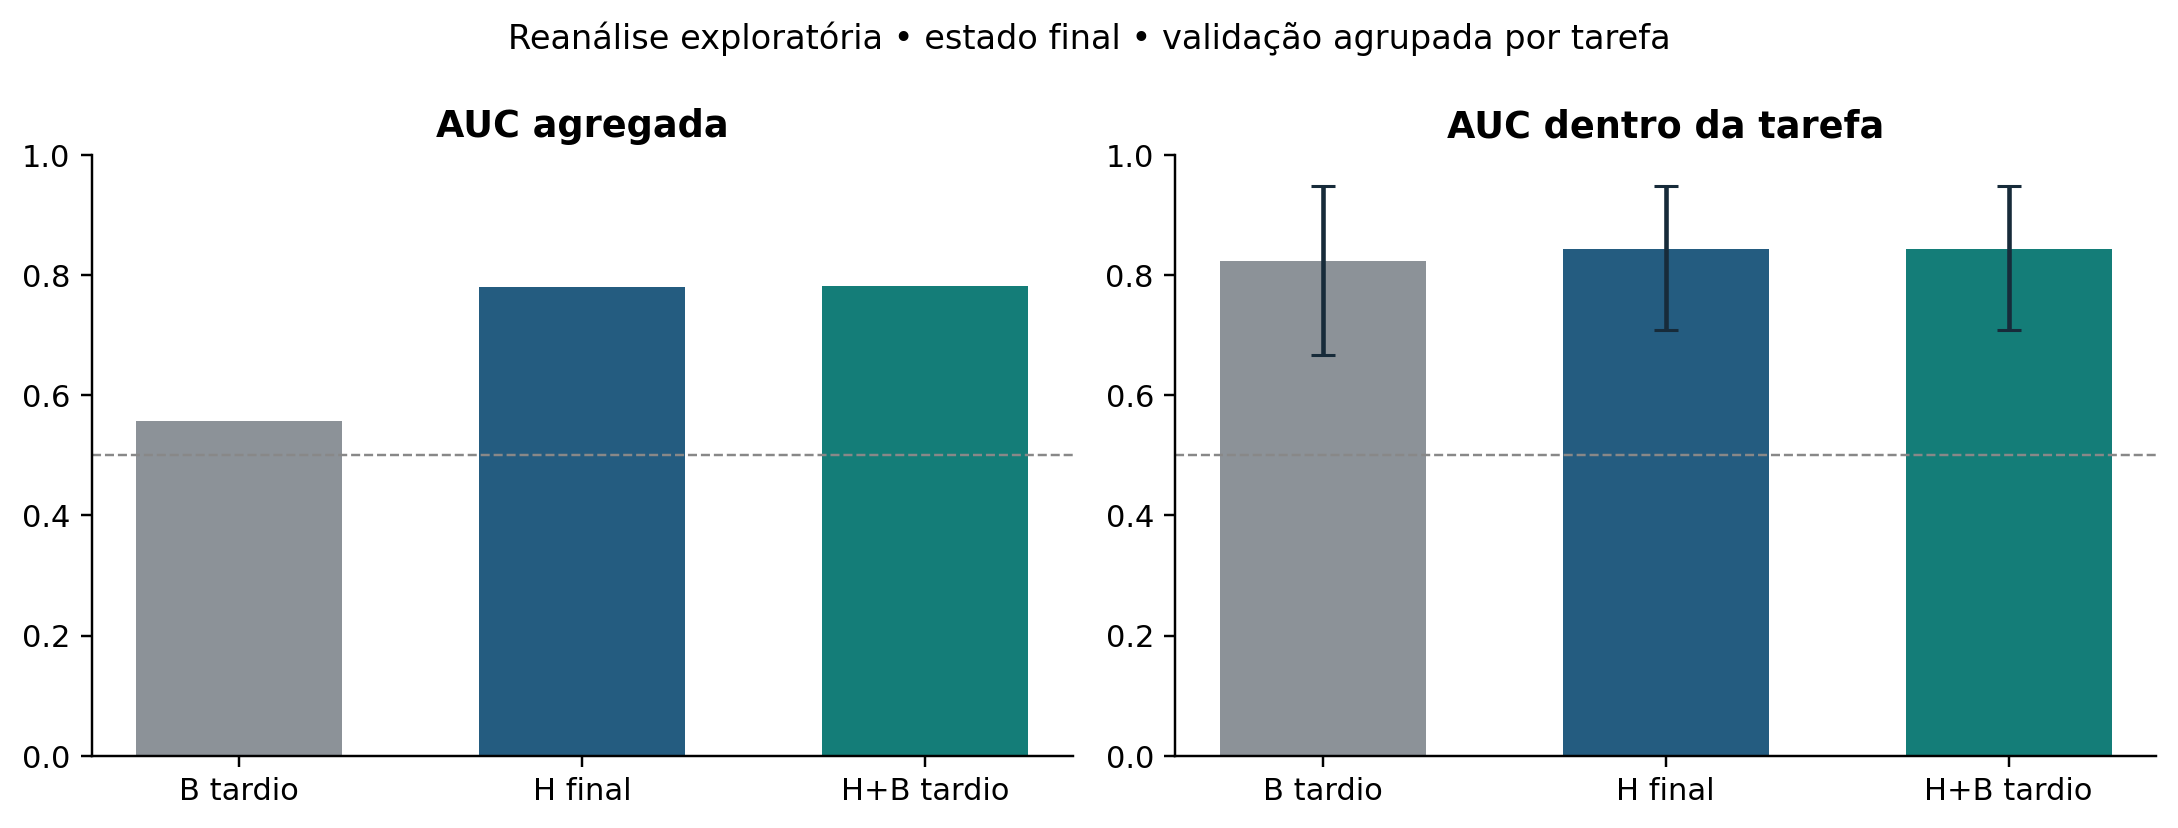

,efeito,estimate,ci95,tasks,replications,seed,unit
0,ΔWT-AUC: H+B tardio − B tardio,0.0208,"[-0.10416666666666666, 0.15651041666666524]",16,2000,20261012,task_id
1,Δlog loss: H+B tardio − B tardio,-0.1433,"[-0.2315164347450523, -0.04295778944747924]",30,2000,20261012,task_id


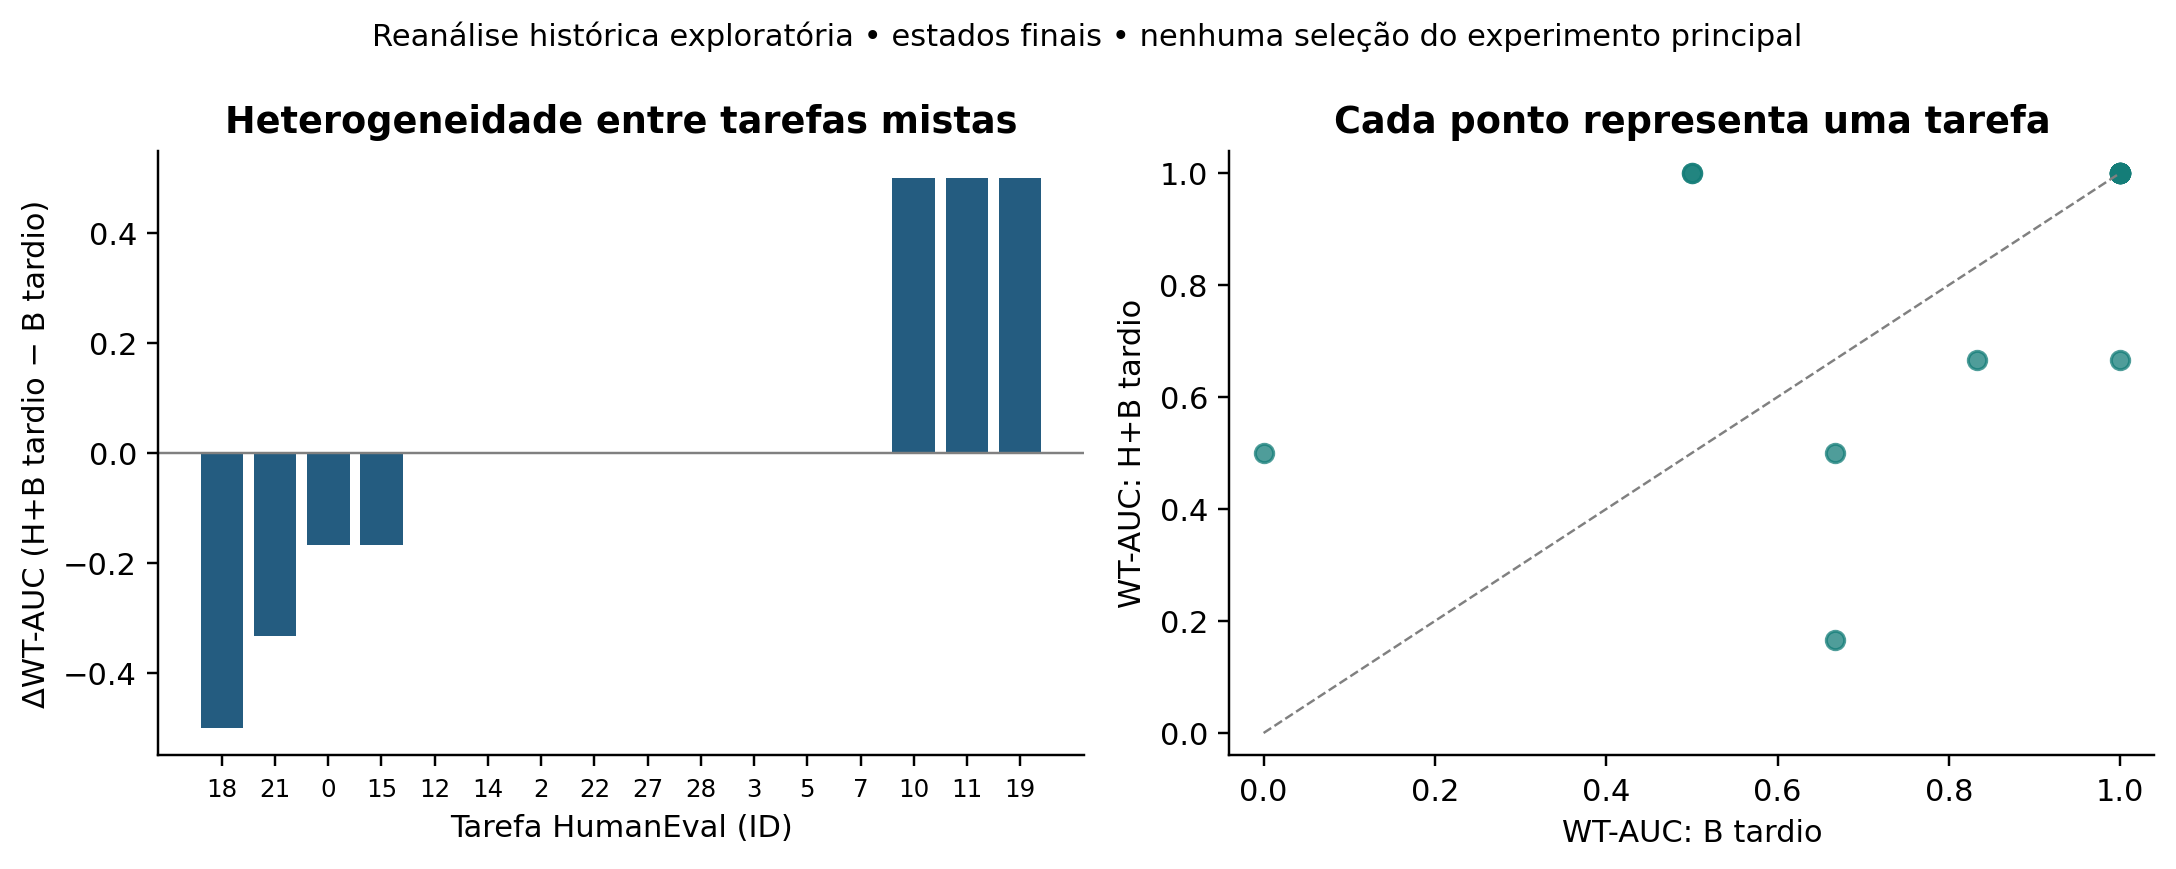

In [15]:
late = evidence["legacy_reanalysis"]
metrics = pd.DataFrame([{**{k: row[k] for k in ["family", "roc_auc", "within_task_auc", "log_loss", "brier", "mixed_tasks"]},
                         "WT-AUC IC95%": row["wt_auc_interval"]["ci95"]} for row in late["metrics"]])
display(metrics)
display(Image(filename=str(REPORT / "figures/legacy_late_probes.png")))
display(pd.DataFrame([{"efeito": "ΔWT-AUC: H+B tardio − B tardio", **late["delta_wt_auc"]},
                      {"efeito": "Δlog loss: H+B tardio − B tardio", **late["delta_log_loss"]}]))

by_task = REPORT / "figures/legacy_incremental_by_task.png"
if by_task.exists():
    display(Image(filename=str(by_task)))


**Leitura:** discriminação, ganho incremental e utilidade operacional são perguntas
distintas. O intervalo de ΔWT-AUC inclui zero nesta reanálise. A redução da log loss
sustenta melhoria probabilística no regime histórico, condicionada aos modelos ajustados,
mas não demonstra ganho de ordenação intratarefa nem utilidade precoce.

Os intervalos usam 2.000 reamostragens pareadas de tarefas. Na WT-AUC, a população
é o subconjunto de tarefas mistas; na perda, todas as tarefas. O bootstrap mantém
fixos os modelos OOF e não representa toda a incerteza de retreinamento.

A antiga AUC máxima de um único split não é diretamente comparável à avaliação
aninhada completa acima. Nenhum dos dois resultados demonstra predição antes do término.


## 4. Estado da coleta e validação técnica

Os bancos v0.1 e v0.2 têm definições diferentes de rótulo/margem e sementes
dependentes da versão. Os resultados não são agrupados. Uma sessão parcial pode
demonstrar viabilidade técnica, mas não permite escolher a temperatura nem estimar
o efeito confirmatório. Tempos de desenvolvimento podem incluir contenção local.


,version,status,attempts,planned,tasks,completion_tokens,generation_seconds,peak_reserved_mib,temperature_selected,causal_validation,seed_validation,label_definition
0,0.1,partial,39,960,13,2693,427.1611,4598.0,NaN,True,True,EvalPlus pass AND not truncated
1,0.2,completed,960,960,32,71360,14023.2437,4996.0,1.0,True,True,functional EvalPlus pass


,version,temperature,attempts,correct,truncated,planned,mean_tokens
0,0.1,0.6,13,8,0,320,78.3846
1,0.1,0.8,13,8,0,320,68.3077
2,0.1,1.0,13,4,0,320,60.4615
3,0.2,0.6,320,186,1,320,73.1937
4,0.2,0.8,320,180,0,320,71.7031
5,0.2,1.0,320,171,0,320,78.1031


**Histórico de exposição:** {'legacy_tasks': 30, 'current_pilot_overlap': 4, 'current_reserved_overlap': 26}. Presença em arquivos demonstra geração prévia, não quais resultados foram inspecionados.

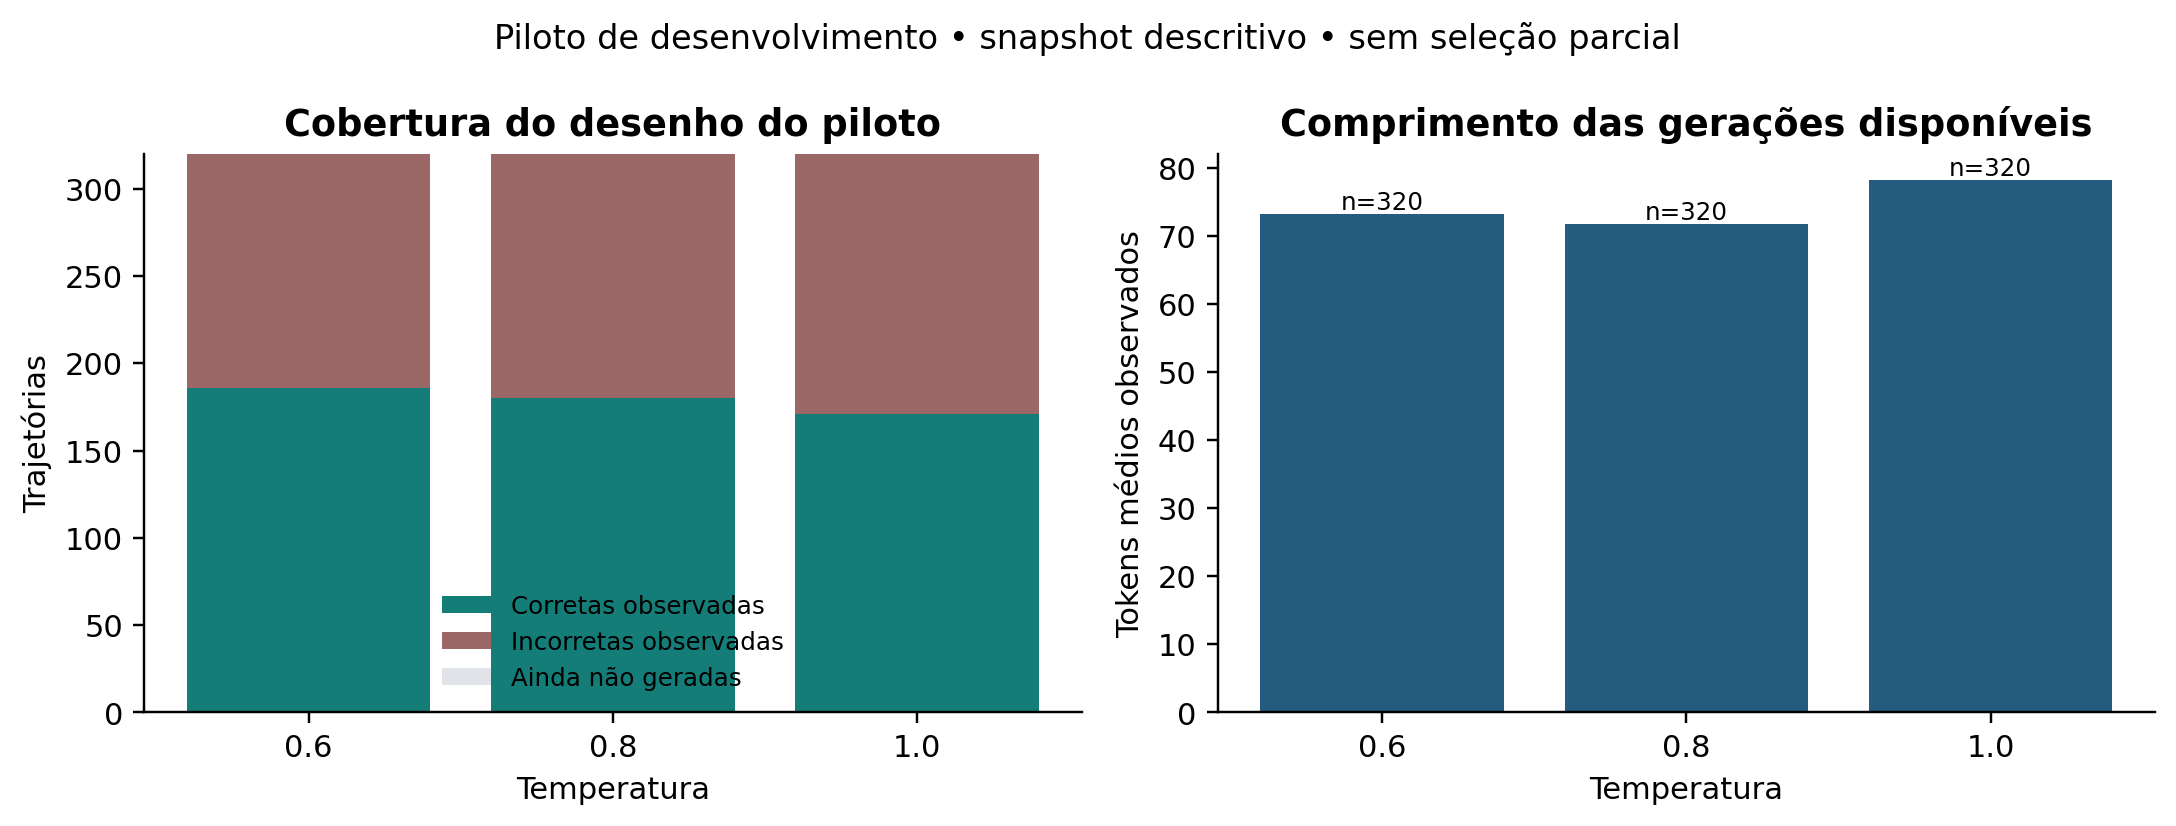

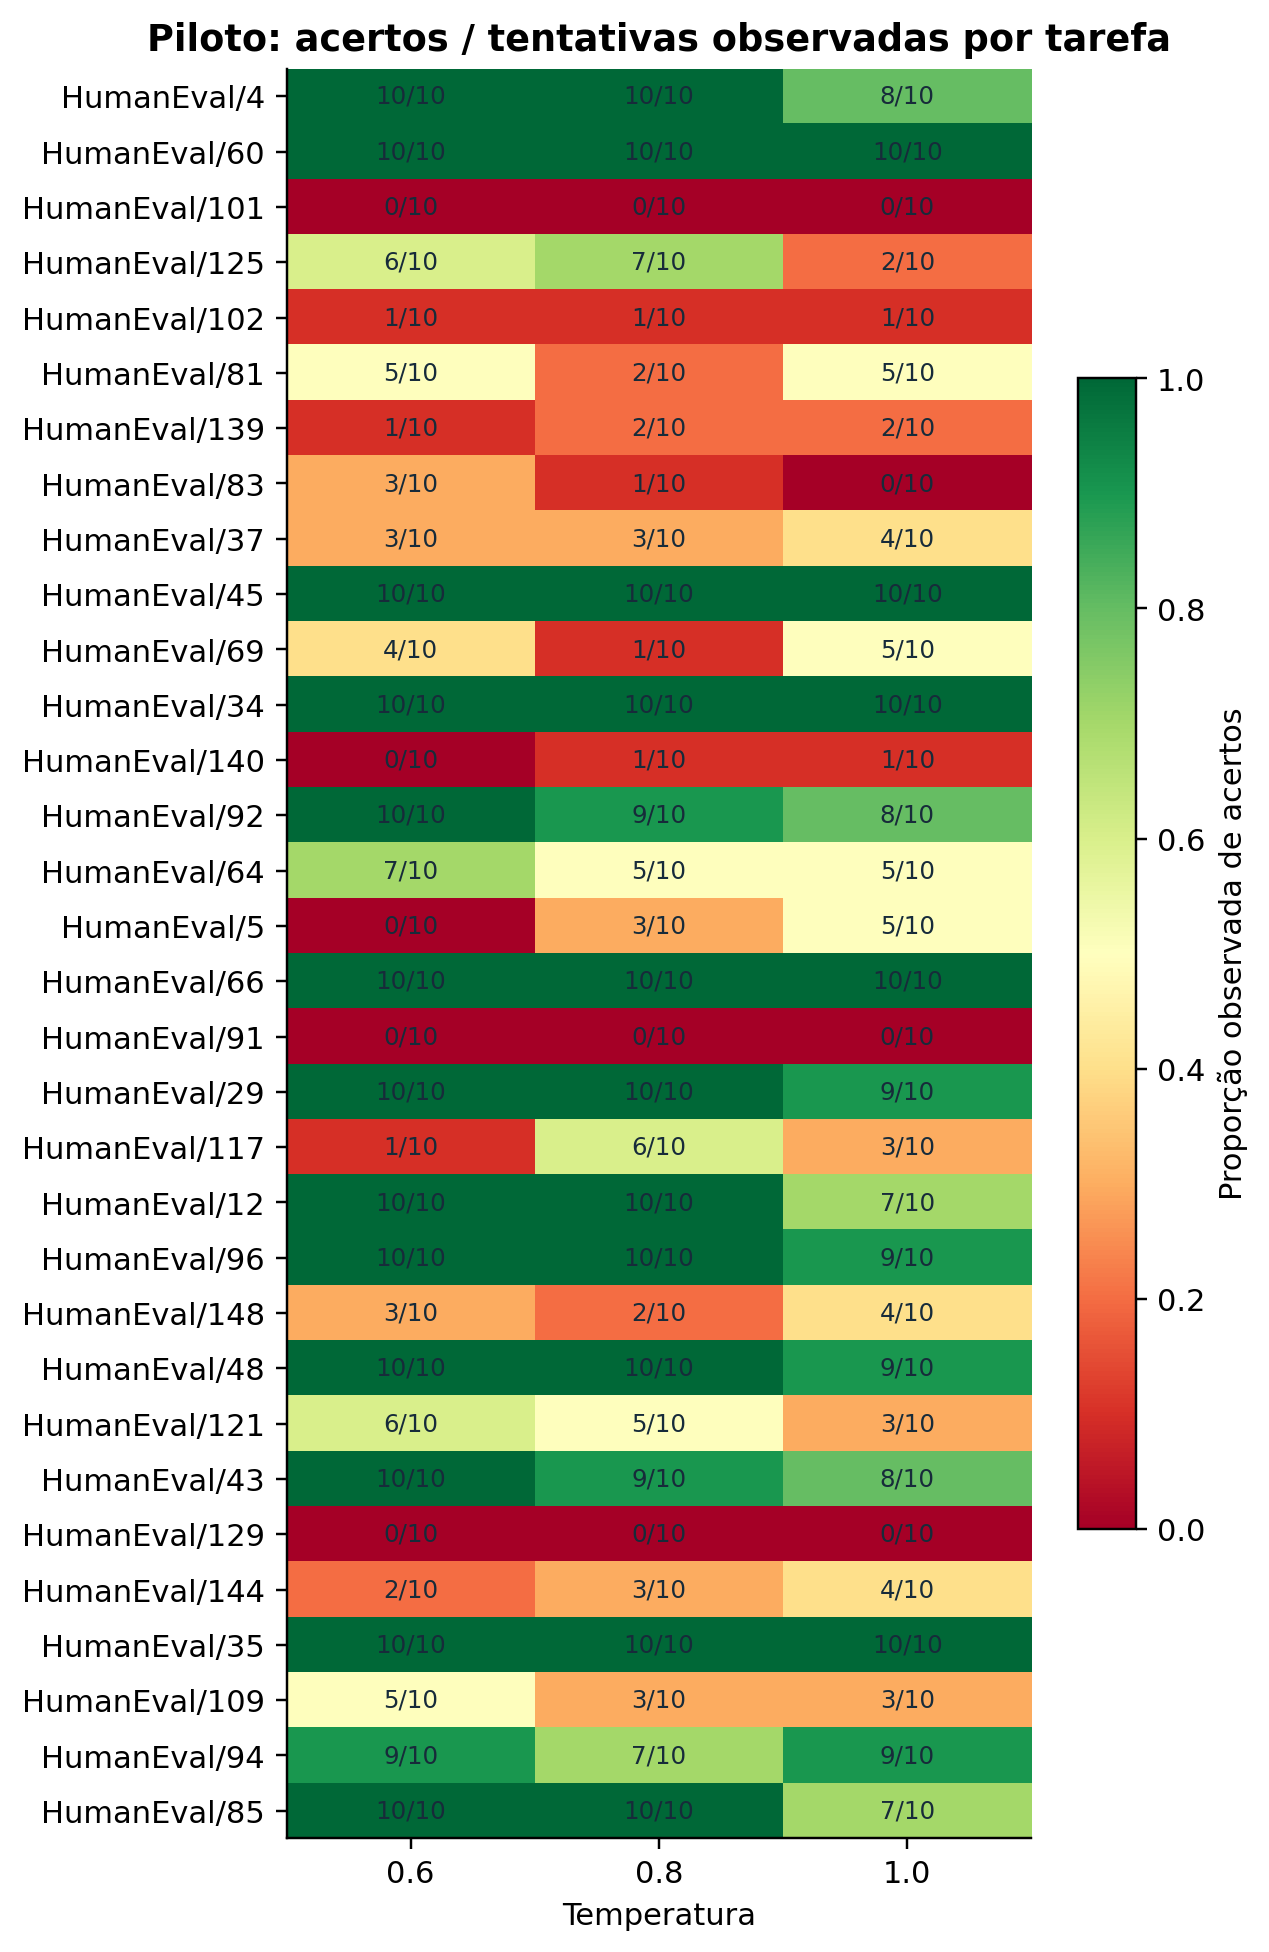

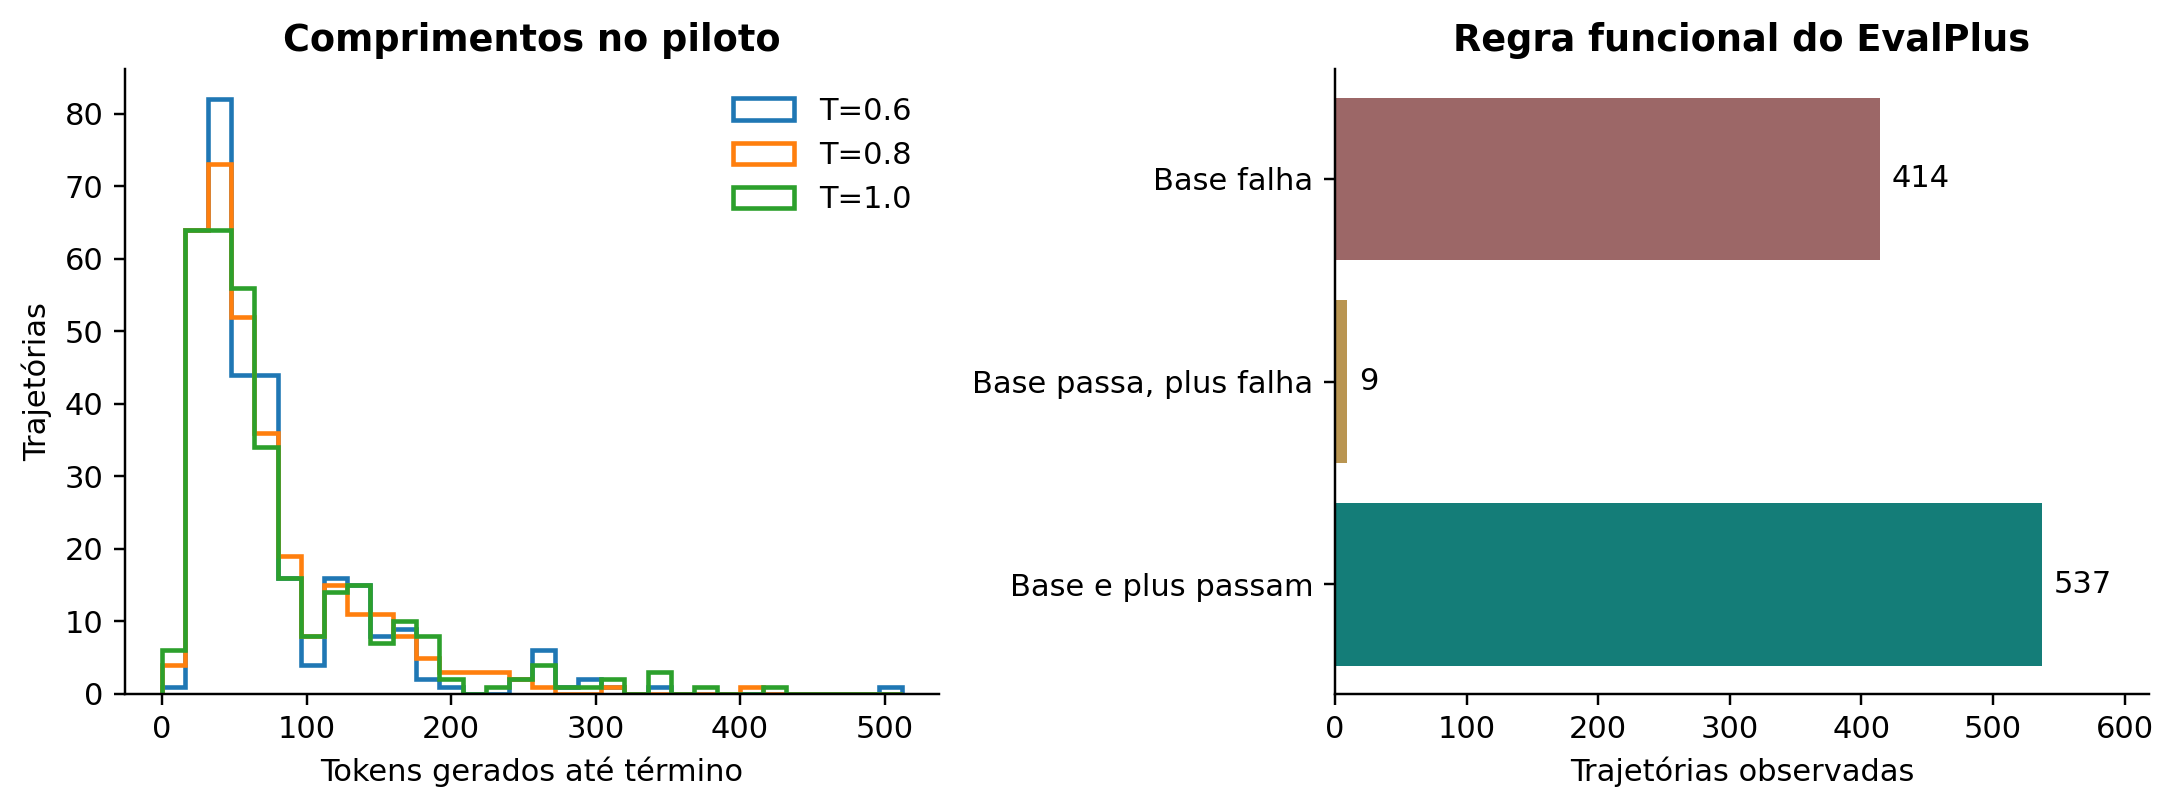

In [16]:
display(pd.DataFrame(evidence["pilot"]))
display(pd.read_csv(REPORT / "tables/pilot_temperatures.csv"))
display(Markdown("**Histórico de exposição:** " + str(evidence["exposure"]) +
                ". Presença em arquivos demonstra geração prévia, não quais resultados foram inspecionados."))

progress = REPORT / "figures/pilot_sampling_progress.png"
if progress.exists():
    display(Image(filename=str(progress)))

for name in ["pilot_task_temperature_grid", "pilot_lengths_and_verifier"]:
    path = REPORT / f"figures/{name}.png"
    if path.exists():
        display(Image(filename=str(path)))


## Decisões das perguntas principais

As decisões derivam dos critérios fixados, sem escolher o melhor resultado
secundário. Bootstrap condicional aos modelos OOF; cada tarefa é uma unidade.
Permutação de associação não substitui comparação incremental com B.


In [17]:
confirmatory_path = ROOT / "reports/protocol_v0.2/results.json"
if confirmatory_path.exists():
    confirmatory = json.loads(confirmatory_path.read_text(encoding="utf-8"))
    display(Markdown("### Artefato confirmatório disponível posteriormente"))
    display(confirmatory["signal"]["H2"])
    display(confirmatory["policies"].get("H3", {}))
else:
    display(Markdown("**Não há artefato confirmatório para apresentar nesta versão.**"))


### Artefato confirmatório disponível posteriormente

{'supported': False,
 'checkpoint': 32,
 'delta_hb_minus_b': {'estimate': -0.04702865751183576,
  'ci95': [-0.09937495818447424, 0.005583498622638421],
  'tasks': 92,
  'replications': 2000,
  'seed': 20260921,
  'unit': 'task_id'},
 'descriptive_delta_h_minus_b': {'estimate': -0.06004633395733728,
  'ci95': [-0.1143251150204028, -0.003948685130266649],
  'tasks': 92,
  'replications': 2000,
  'seed': 20260921,
  'unit': 'task_id'},
 'permutation': {'p_value': 0.030996900309969003,
  'folds': [{'fold': 0,
    'p_value': 0.1100889911008899,
    'observed_wt_auc': 0.558784776511577,
    'mixed_tasks': 19,
    'seed': 20260921},
   {'fold': 1,
    'p_value': 0.006199380061993801,
    'observed_wt_auc': 0.594928908515974,
    'mixed_tasks': 22,
    'seed': 20260922},
   {'fold': 2,
    'p_value': 0.017598240175982403,
    'observed_wt_auc': 0.5929434742363664,
    'mixed_tasks': 18,
    'seed': 20260923},
   {'fold': 3,
    'p_value': 0.07879212078792121,
    'observed_wt_auc': 0.568611816

{'offline_statistical_support': False,
 'online_replay_validated': True,
 'incremental_over_observables': False,
 'system_result_finalized': False,
 'primary_budget': 20,
 'h2_supported': False,
 'operational_benefit_claim_supported': False,
 'interpretation': 'Predeclared diagnostic only; no operational benefit claim when H2 is unsupported'}

## 6. Proveniência e verificações

As tabelas e figuras derivam de `evidence.json` e dos arquivos listados abaixo.
Se um banco crescer após esta entrega, o hash deixa de coincidir: reconstrua a
evidência e o notebook. Um arquivo bruto ausente não invalida a visualização dos
resultados arquivados, mas impede sua rechecagem local.


In [18]:
provenance = []
for relative, expected in evidence["inputs"].items():
    path = ROOT / relative
    actual = hashlib.sha256(path.read_bytes()).hexdigest() if path.exists() else None
    provenance.append({"arquivo": relative, "sha256": expected[:16] + "…",
                       "checagem": "confere" if actual == expected else "ausente" if actual is None else "alterado"})
display(pd.DataFrame(provenance))

import xml.etree.ElementTree as ET
test_report = ROOT / "reports/research/test_results_v0.2.xml"
if test_report.exists():
    suites = ET.parse(test_report).getroot().iter("testsuite")
    display(pd.DataFrame([{k: suite.attrib.get(k) for k in ["tests", "failures", "errors", "skipped"]} for suite in suites]))


,arquivo,sha256,checagem
0,runs/phase2/qwen15b_temp08_n5.jsonl,815fed3a74098dcc…,confere
1,runs/phase3/qwen_phase3_probe/metadata.jsonl,7b0003073397e669…,confere
2,runs/phase3/qwen_phase3_probe/manifest.json,1cf4ea83011c089a…,confere
3,runs/phase3/qwen_phase3_probe/activations.npz,dd88bd41760dc68e…,confere
4,runs/candidate_bank/pilot_v0.1/trajectories.jsonl,7adefec0e9cadaf0…,confere
...,...,...,...
178,scripts/render_main_manuscript.py,f9c1a4414bcd7e3d…,confere
179,scripts/supplemental_publication.py,b00ffa8ab4942371…,confere
180,scripts/build_manuscript.py,61a96521d3a7bbe5…,confere
181,scripts/audit_research_delivery.py,17d87df2e541a6fc…,confere


,tests,failures,errors,skipped
0,157,0,0,0


## 7. Reprodução e continuidade

Na raiz do repositório, usando o Python do ambiente:

```powershell
.venv/Scripts/python.exe -m pytest -q
.venv/Scripts/python.exe scripts/build_research_delivery.py --reanalyze-legacy
.venv/Scripts/python.exe scripts/build_final_notebook.py --execute
.venv/Scripts/python.exe scripts/build_manuscript.py --compile
```

A reanálise usa CPU e os arquivos históricos de `runs/`. O notebook em si apenas
lê as tabelas e figuras. Veja `docs/research_workflow.md` para coleta, congelamento,
probes e transferência. A execução integral foi autorizada pelo estudante. O desenho e seus fontes
estão copiados em `reports/research/execution_freeze_v0.2/`. A aprovação do
orientador permanece pendente; não se reivindica pré-registro independente.

O manuscrito está em `tcc/main.typ` e o PDF em `tcc/build/manuscrito.pdf`.
